In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_path = "/content/drive/MyDrive/detaset"

print("Dataset path:")
print(dataset_path)

Dataset path:
/content/drive/MyDrive/detaset


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.20.0


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20

CASIA_PATH = os.path.join(
    dataset_path,
    "CASIA2"
)

AUTHENTIC_PATH = os.path.join(
    CASIA_PATH,
    "Au"
)

TAMPERED_PATH = os.path.join(
    CASIA_PATH,
    "Tp"
)

print("CASIA2 path:", CASIA_PATH)
print("Authentic (Au):", AUTHENTIC_PATH)
print("Tampered (Tp):", TAMPERED_PATH)


CASIA2 path: /content/drive/MyDrive/detaset/CASIA2
Authentic (Au): /content/drive/MyDrive/detaset/CASIA2/Au
Tampered (Tp): /content/drive/MyDrive/detaset/CASIA2/Tp


In [ ]:
print("CASIA2 exists:", os.path.exists(CASIA_PATH))
print("Au exists:", os.path.exists(AUTHENTIC_PATH))
print("Tp exists:", os.path.exists(TAMPERED_PATH))

CASIA2 exists: True
Au exists: True
Tp exists: True


In [ ]:
print("Authentic (Au) files:", len(os.listdir(AUTHENTIC_PATH)))
print("Tampered (Tp) files :", len(os.listdir(TAMPERED_PATH)))

Authentic (Au) files: 7492
Tampered (Tp) files : 5125


In [ ]:
def get_valid_images(folder, label):

    paths = []
    labels = []

    valid_extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp"
    )

    skipped = 0

    for root, dirs, files in os.walk(folder):

        for filename in files:

            filepath = os.path.join(root, filename)

            # Check extension
            if not filename.lower().endswith(valid_extensions):
                skipped += 1
                continue

            # Check actual image
            try:
                with Image.open(filepath) as img:
                    img.verify()

                paths.append(filepath)
                labels.append(label)

            except Exception:
                skipped += 1

    print("Folder:", folder)
    print("Valid images:", len(paths))
    print("Skipped files:", skipped)

    return paths, labels

In [ ]:
auth_paths, auth_labels = get_valid_images(
    AUTHENTIC_PATH,
    0
)

tampered_paths, tampered_labels = get_valid_images(
    TAMPERED_PATH,
    1
)

image_paths = auth_paths + tampered_paths
labels = auth_labels + tampered_labels

print("\n==============================")
print("DATASET SUMMARY")
print("==============================")

print("Authentic images:", len(auth_paths))
print("Tampered images :", len(tampered_paths))
print("Total images    :", len(image_paths))

Folder: /content/drive/MyDrive/detaset/CASIA2/Au
Valid images: 7491
Skipped files: 1
Folder: /content/drive/MyDrive/detaset/CASIA2/Tp
Valid images: 2064
Skipped files: 3061

DATASET SUMMARY
Authentic images: 7491
Tampered images : 2064
Total images    : 9555


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images  :", len(X_train))
print("Validation images:", len(X_val))
print("Testing images   :", len(X_test))

Training images  : 6688
Validation images: 1433
Testing images   : 1434


In [ ]:
def load_image(path, label):

    def read_image(path_bytes):

        path_str = path_bytes.decode("utf-8")

        with Image.open(path_str) as img:

            img = img.convert("RGB")

            img = img.resize(
                (IMG_SIZE, IMG_SIZE)
            )

            return np.array(
                img,
                dtype=np.float32
            )

    image = tf.numpy_function(
        read_image,
        [path],
        tf.float32
    )

    image.set_shape(
        [IMG_SIZE, IMG_SIZE, 3]
    )

    # Normalize pixel values: 0-255 -> 0-1
    image = image / 255.0

    return image, tf.cast(
        label,
        tf.float32
    )

In [ ]:
def create_dataset(paths, labels, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [ ]:
train_ds = create_dataset(
    X_train,
    y_train,
    shuffle=True
)

val_ds = create_dataset(
    X_val,
    y_val,
    shuffle=False
)

test_ds = create_dataset(
    X_test,
    y_test,
    shuffle=False
)

print("Train dataset ready.")
print("Validation dataset ready.")
print("Test dataset ready.")

Train dataset ready.
Validation dataset ready.
Test dataset ready.


In [ ]:
for images, labels_batch in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels_batch.shape)
    print("First 10 labels:", labels_batch[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [1. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Pre-trained layers ko initially freeze karenge
base_model.trainable = False

model = models.Sequential([

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.4),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

checkpoint_path = (
    "/content/drive/MyDrive/"
    "TamperVision_best.keras"
)

callbacks = [

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks ready!")
print("Best model will be saved at:")
print(checkpoint_path)

Callbacks ready!
Best model will be saved at:
/content/drive/MyDrive/TamperVision_best.keras


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6843 - loss: 0.6777 - precision: 0.2542 - recall: 0.2633
Epoch 1: val_accuracy improved from None to 0.77669, saving model to /content/drive/MyDrive/TamperVision_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TamperVision_best.keras
209/209 ━━━━━━━━━━━━━━━━━━━━ 477s 2s/step - accuracy: 0.7095 - loss: 0.6475 - precision: 0.2949 - recall: 0.2478 - val_accuracy: 0.7767 - val_loss: 0.5060 - val_precision: 0.4586 - val_recall: 0.1974 - learning_rate: 1.0000e-04
Epoch 2/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7607 - loss: 0.5239 - precision: 0.3803 - recall: 0.2623
Epoch 2: val_accuracy improved from 0.77669 to 0.79065, saving model to /content/drive/MyDrive/TamperVision_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TamperVision_best.keras
209/209 ━━━━━━━━━━━━━━━━━━━━ 586s 3s/step - accuracy: 0.7656 - loss: 0.5226 - precision: 0.4328 - recall: 0.2740 - val_accuracy: 

In [ ]:
test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\n==============================")
print("TEST RESULTS")
print("==============================")

print("Test Loss     :", test_results[0])
print("Test Accuracy :", test_results[1])
print("Test Precision:", test_results[2])
print("Test Recall   :", test_results[3])

45/45 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.8138 - loss: 0.4402 - precision: 0.6287 - recall: 0.3387

TEST RESULTS
Test Loss     : 0.44021230936050415
Test Accuracy : 0.8138075470924377
Test Precision: 0.628742516040802
Test Recall   : 0.33870968222618103



CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Authentic     0.8382    0.9448    0.8883      1124
    Tampered     0.6287    0.3387    0.4403       310

    accuracy                         0.8138      1434
   macro avg     0.7335    0.6418    0.6643      1434
weighted avg     0.7929    0.8138    0.7915      1434


CONFUSION MATRIX
[[1062   62]
 [ 205  105]]


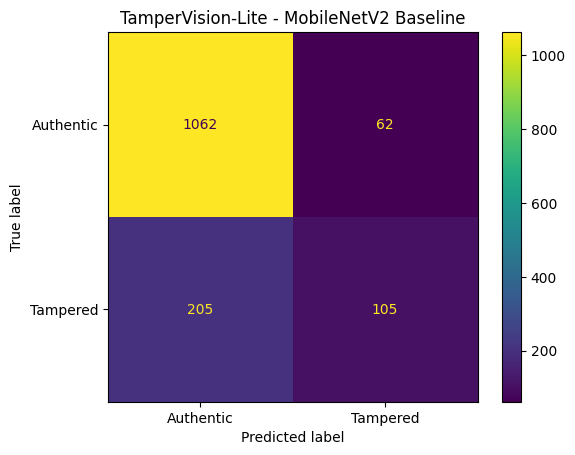

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = []
y_pred = []

for images, labels_batch in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        labels_batch.numpy().astype(int)
    )

    y_pred.extend(
        (predictions.flatten() >= 0.5).astype(int)
    )

print("\n==============================")
print("CLASSIFICATION REPORT")
print("==============================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Tampered"
        ],
        digits=4
    )
)

print("\n==============================")
print("CONFUSION MATRIX")
print("==============================")

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Authentic",
        "Tampered"
    ]
)

disp.plot()
plt.title("TamperVision-Lite - MobileNetV2 Baseline")
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

# =========================================================
# SRM FILTER LAYER
# =========================================================

class SRMFilter(layers.Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        # Three commonly used high-pass residual filters
        srm_filters = tf.constant([
            [
                [0, 0, 0],
                [0, -1, 1],
                [0, 0, 0]
            ],

            [
                [0, 0, 0],
                [0, -1, 0],
                [0, 1, 0]
            ],

            [
                [0, 0, 0],
                [-1, 0, 1],
                [0, 0, 0]
            ]
        ], dtype=tf.float32)

        self.srm_filters = srm_filters

    def build(self, input_shape):

        channels = input_shape[-1]

        # Create depthwise kernels:
        # [3, 3, RGB channels, 3 filters]
        kernels = []

        for c in range(channels):

            channel_filters = self.srm_filters

            kernels.append(channel_filters)

        kernel = tf.stack(kernels, axis=2)

        self.kernel = tf.cast(
            kernel,
            tf.float32
        )

        super().build(input_shape)

    def call(self, inputs):

        residual = tf.nn.depthwise_conv2d(
            inputs,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

        return residual


# =========================================================
# INPUT
# =========================================================

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="input_image"
)


# =========================================================
# BRANCH 1 — SRM
# =========================================================

srm = SRMFilter(
    name="srm_filter"
)(inputs)

srm = layers.Conv2D(
    32,
    (3, 3),
    padding="same",
    activation="relu",
    name="srm_conv1"
)(srm)

srm = layers.BatchNormalization()(srm)

srm = layers.MaxPooling2D(
    (2, 2)
)(srm)

srm = layers.Conv2D(
    64,
    (3, 3),
    padding="same",
    activation="relu",
    name="srm_conv2"
)(srm)

srm = layers.BatchNormalization()(srm)

srm = layers.GlobalAveragePooling2D(
    name="srm_features"
)(srm)


# =========================================================
# BRANCH 2 — MobileNetV2
# =========================================================

mobilenet = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Initially freeze pretrained MobileNet
mobilenet.trainable = False

rgb_features = mobilenet(inputs)

rgb_features = layers.GlobalAveragePooling2D(
    name="mobilenet_features"
)(rgb_features)


# =========================================================
# FEATURE FUSION
# =========================================================

fusion = layers.Concatenate(
    name="feature_fusion"
)([
    srm,
    rgb_features
])


fusion = layers.BatchNormalization()(fusion)

fusion = layers.Dense(
    256,
    activation="relu",
    name="fusion_dense"
)(fusion)

fusion = layers.Dropout(
    0.4
)(fusion)


# =========================================================
# CLASSIFIER
# =========================================================

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="tampering_output"
)(fusion)


# =========================================================
# FINAL MODEL
# =========================================================

fusion_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="TamperVision_Lite_SRM_MobileNet_Fusion"
)


fusion_model.summary()

Model: "TamperVision_Lite_SRM_MobileNet_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_filter          │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (SRMFilter)         │ 9)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_conv1 (Conv2D)  │ (None, 224, 224,  │      2,624 │ srm_filter[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ srm_conv1[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_conv2 (Conv2D)  │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ srm_conv2[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ input_image[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ srm_features        │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_features  │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 1344)      │          0 │ srm_features[0][… │
│ (Concatenate)       │                   │            │ mobilenet_featur… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1344)      │      5,376 │ feature_fusion[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense        │ (None, 256)       │    344,320 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ fusion_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tampering_output    │ (None, 1)         │        257 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,629,441 (10.03 MB)

 Trainable params: 368,577 (1.41 MB)

 Non-trainable params: 2,260,864 (8.62 MB)

In [ ]:
fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

print("SRM + MobileNetV2 Fusion Model compiled successfully!")

SRM + MobileNetV2 Fusion Model compiled successfully!


In [ ]:
fusion_checkpoint_path = (
    "/content/drive/MyDrive/"
    "TamperVision_SRM_MobileNet_best.keras"
)

fusion_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        fusion_checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fusion model callbacks ready!")
print("Best model will be saved at:")
print(fusion_checkpoint_path)

Fusion model callbacks ready!
Best model will be saved at:
/content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras


In [ ]:
fusion_history = fusion_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=fusion_callbacks
)

Epoch 1/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.5811 - loss: 0.8049 - precision: 0.2586 - recall: 0.4605
Epoch 1: val_accuracy improved from None to 0.78786, saving model to /content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras
209/209 ━━━━━━━━━━━━━━━━━━━━ 1776s 8s/step - accuracy: 0.6658 - loss: 0.6725 - precision: 0.2867 - recall: 0.3675 - val_accuracy: 0.7879 - val_loss: 0.4815 - val_precision: 0.5159 - val_recall: 0.2621 - learning_rate: 1.0000e-04
Epoch 2/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.7879 - loss: 0.4915 - precision: 0.4945 - recall: 0.3444
Epoch 2: val_accuracy did not improve from 0.78786
209/209 ━━━━━━━━━━━━━━━━━━━━ 1821s 9s/step - accuracy: 0.7777 - loss: 0.5034 - precision: 0.4790 - recall: 0.3322 - val_accuracy: 0.7872 - val_loss: 0.4662 - val_precision: 0.5169 - val_recall: 0.1974 - learning_rate: 1.0000e-04
Epoch 3/20
209/209 ━━

In [ ]:
# ============================================
# CELL 23A: IMPORTS FOR TEST EVALUATION
# ============================================

import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Imports successful.")

Imports successful.


In [ ]:
# ============================================
# CELL 23A: RESTORE SRM FILTER DEFINITION
# ============================================

import tensorflow as tf
from tensorflow.keras import layers

class SRMFilter(layers.Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        srm_filters = tf.constant([
            [[0, 0, 0],
             [0, -1, 1],
             [0, 0, 0]],

            [[0, 0, 0],
             [0, -1, 0],
             [0, 1, 0]],

            [[0, 0, 0],
             [-1, 0, 1],
             [0, 0, 0]]
        ], dtype=tf.float32)

        self.srm_filters = srm_filters

    def build(self, input_shape):

        channels = input_shape[-1]

        kernels = []

        for c in range(channels):
            kernels.append(self.srm_filters)

        kernel = tf.stack(kernels, axis=2)

        self.kernel = tf.cast(kernel, tf.float32)

        super().build(input_shape)

    def call(self, inputs):

        residual = tf.nn.depthwise_conv2d(
            inputs,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

        return residual


print("SRMFilter restored successfully.")

SRMFilter restored successfully.


In [ ]:
# ============================================
# CELL 24A: FIND STAGE 1 CHECKPOINT
# ============================================

import os

# Make sure Google Drive is mounted
from google.colab import drive
drive.mount("/content/drive")

# Search for the saved Stage 1 model
search_root = "/content/drive/MyDrive"

matches = []

for root, dirs, files in os.walk(search_root):
    for file in files:
        if file.endswith(".keras") and "TamperVision" in file:
            matches.append(os.path.join(root, file))

print("\nFound model files:")
print("==============================")

if matches:
    for path in matches:
        print(path)
else:
    print("No TamperVision .keras model found.")

Mounted at /content/drive

Found model files:
/content/drive/MyDrive/TamperVision_best.keras
/content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras


In [ ]:
# ============================================
# CELL 24A: RESTORE TEST DATASET
# ============================================

import os
import numpy as np
import tensorflow as tf
from PIL import Image

IMG_SIZE = 224
BATCH_SIZE = 32

dataset_path = "/content/drive/MyDrive/detaset"

CASIA_PATH = os.path.join(dataset_path, "CASIA2")
AUTHENTIC_PATH = os.path.join(CASIA_PATH, "Au")
TAMPERED_PATH = os.path.join(CASIA_PATH, "Tp")


# --------------------------------------------
# Find valid images
# --------------------------------------------

def get_valid_images(folder, label):

    paths = []
    labels = []

    valid_extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp"
    )

    for root, dirs, files in os.walk(folder):

        for filename in files:

            filepath = os.path.join(root, filename)

            if not filename.lower().endswith(valid_extensions):
                continue

            try:
                with Image.open(filepath) as img:
                    img.verify()

                paths.append(filepath)
                labels.append(label)

            except Exception:
                pass

    return paths, labels


# --------------------------------------------
# Load image paths
# --------------------------------------------

auth_paths, auth_labels = get_valid_images(
    AUTHENTIC_PATH,
    0
)

tampered_paths, tampered_labels = get_valid_images(
    TAMPERED_PATH,
    1
)

image_paths = auth_paths + tampered_paths
labels = auth_labels + tampered_labels

print("Authentic images :", len(auth_paths))
print("Tampered images  :", len(tampered_paths))
print("Total images     :", len(image_paths))


# --------------------------------------------
# Recreate SAME split
# --------------------------------------------

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset split:")
print("Train      :", len(X_train))
print("Validation :", len(X_val))
print("Test       :", len(X_test))


# --------------------------------------------
# Image loader
# --------------------------------------------

def load_image(path, label):

    def read_image(path_bytes):

        path_str = path_bytes.decode("utf-8")

        with Image.open(path_str) as img:

            img = img.convert("RGB")
            img = img.resize(
                (IMG_SIZE, IMG_SIZE)
            )

            return np.array(
                img,
                dtype=np.float32
            )

    image = tf.numpy_function(
        read_image,
        [path],
        tf.float32
    )

    image.set_shape(
        [IMG_SIZE, IMG_SIZE, 3]
    )

    image = image / 255.0

    return image, tf.cast(
        label,
        tf.float32
    )


# --------------------------------------------
# Create datasets
# --------------------------------------------

def create_dataset(
    paths,
    labels,
    shuffle=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(paths),
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(
    X_train,
    y_train,
    shuffle=True
)

val_ds = create_dataset(
    X_val,
    y_val,
    shuffle=False
)

test_ds = create_dataset(
    X_test,
    y_test,
    shuffle=False
)

print("\nTest dataset restored successfully.")

# Quick check
for images, labels_batch in test_ds.take(1):

    print("Test image batch :", images.shape)
    print("Test label batch :", labels_batch.shape)

Authentic images : 7491
Tampered images  : 2064
Total images     : 9555

Dataset split:
Train      : 6688
Validation : 1433
Test       : 1434

Test dataset restored successfully.
Test image batch : (32, 224, 224, 3)
Test label batch : (32,)


In [ ]:
# ============================================
# CELL 24: BASELINE vs STAGE 1 COMPARISON
# ============================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------
# Load best Stage 1 model
# --------------------------------------------

fusion_checkpoint_path = "/content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras"

best_fusion_model = tf.keras.models.load_model(
    fusion_checkpoint_path,
    custom_objects={"SRMFilter": SRMFilter}
)

print("Best Stage 1 model loaded successfully.")

# --------------------------------------------
# Generate Stage 1 test predictions
# --------------------------------------------

y_true_stage1 = []
y_prob_stage1 = []

for images, labels_batch in test_ds:

    probabilities = best_fusion_model.predict(
        images,
        verbose=0
    ).ravel()

    y_prob_stage1.extend(probabilities)
    y_true_stage1.extend(labels_batch.numpy())

y_true_stage1 = np.array(y_true_stage1).astype(int)
y_prob_stage1 = np.array(y_prob_stage1)

# Threshold = 0.5
y_pred_stage1 = (
    y_prob_stage1 >= 0.5
).astype(int)

# --------------------------------------------
# Calculate Stage 1 metrics
# --------------------------------------------

stage1_accuracy = accuracy_score(
    y_true_stage1,
    y_pred_stage1
)

stage1_precision = precision_score(
    y_true_stage1,
    y_pred_stage1,
    zero_division=0
)

stage1_recall = recall_score(
    y_true_stage1,
    y_pred_stage1,
    zero_division=0
)

stage1_f1 = f1_score(
    y_true_stage1,
    y_pred_stage1,
    zero_division=0
)

# --------------------------------------------
# Baseline results
# --------------------------------------------

baseline_accuracy = 0.8138
baseline_precision = 0.6287
baseline_recall = 0.3387
baseline_f1 = 0.4403

# --------------------------------------------
# Comparison table
# --------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV2",
        "Stage 1 SRM + MobileNetV2 Fusion"
    ],
    "Accuracy": [
        baseline_accuracy,
        stage1_accuracy
    ],
    "Precision": [
        baseline_precision,
        stage1_precision
    ],
    "Tampered Recall": [
        baseline_recall,
        stage1_recall
    ],
    "Tampered F1": [
        baseline_f1,
        stage1_f1
    ]
})

print("\n============================================")
print("BASELINE vs STAGE 1")
print("============================================")

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Tampered Recall": "{:.4f}",
        "Tampered F1": "{:.4f}"
    })
)

# --------------------------------------------
# Improvement
# --------------------------------------------

print("\n============================================")
print("STAGE 1 - CHANGE FROM BASELINE")
print("============================================")

print(
    f"Accuracy       : "
    f"{stage1_accuracy - baseline_accuracy:+.4f}"
)

print(
    f"Precision      : "
    f"{stage1_precision - baseline_precision:+.4f}"
)

print(
    f"Tampered Recall: "
    f"{stage1_recall - baseline_recall:+.4f}"
)

print(
    f"Tampered F1    : "
    f"{stage1_f1 - baseline_f1:+.4f}"
)

Best Stage 1 model loaded successfully.

BASELINE vs STAGE 1


,Model,Accuracy,Precision,Tampered Recall,Tampered F1
0,Baseline MobileNetV2,0.8138,0.6287,0.3387,0.4403
1,Stage 1 SRM + MobileNetV2 Fusion,0.8082,0.5814,0.4032,0.4762



STAGE 1 - CHANGE FROM BASELINE
Accuracy       : -0.0056
Precision      : -0.0473
Tampered Recall: +0.0645
Tampered F1    : +0.0359


In [ ]:
# ============================================
# CELL 25: CONTROLLED FINE-TUNING PREPARATION
# ============================================

# Load the best Stage 1 model
fusion_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/TamperVision_SRM_MobileNet_best.keras",
    custom_objects={"SRMFilter": SRMFilter}
)

# Find MobileNetV2 backbone
mobilenet = None

for layer in fusion_model.layers:
    if isinstance(layer, tf.keras.Model) and "mobilenet" in layer.name.lower():
        mobilenet = layer
        break

if mobilenet is None:
    raise ValueError("MobileNetV2 backbone not found.")

print("MobileNetV2 found:", mobilenet.name)
print("Total layers:", len(mobilenet.layers))

# Freeze all MobileNetV2 layers first
mobilenet.trainable = True

for layer in mobilenet.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
for layer in mobilenet.layers[-30:]:
    layer.trainable = True

print("\nFine-tuning configuration:")
print("Frozen layers  :", sum(
    not layer.trainable for layer in mobilenet.layers
))
print("Trainable layers:", sum(
    layer.trainable for layer in mobilenet.layers
))

MobileNetV2 found: mobilenetv2_1.00_224
Total layers: 154

Fine-tuning configuration:
Frozen layers  : 124
Trainable layers: 30


In [ ]:
# ============================================
# CELL 26: CONTROLLED FINE-TUNING SETUP
# ============================================

# Keep BatchNormalization layers frozen
# to reduce instability during fine-tuning.

for layer in mobilenet.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# Compile with a very low learning rate
fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Fine-tuning checkpoint
finetune_checkpoint_path = (
    "/content/drive/MyDrive/"
    "TamperVision_SRM_MobileNet_FineTuned_best.keras"
)

finetune_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        finetune_checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning setup ready.")
print("Learning rate: 1e-5")
print("Checkpoint:", finetune_checkpoint_path)

Fine-tuning setup ready.
Learning rate: 1e-5
Checkpoint: /content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras


In [ ]:
# ============================================
# CELL 27: CONTROLLED FINE-TUNING TRAINING
# ============================================

FINE_TUNE_EPOCHS = 10

fine_tune_history = fusion_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=finetune_callbacks,
    verbose=1
)

Epoch 1/10
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8798 - loss: 0.2782 - precision: 0.7802 - recall: 0.6131
Epoch 1: val_accuracy improved from None to 0.80321, saving model to /content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras
209/209 ━━━━━━━━━━━━━━━━━━━━ 1803s 8s/step - accuracy: 0.8744 - loss: 0.2872 - precision: 0.7548 - recall: 0.6201 - val_accuracy: 0.8032 - val_loss: 0.4459 - val_precision: 0.5538 - val_recall: 0.4498 - learning_rate: 1.0000e-05
Epoch 2/10
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8845 - loss: 0.2575 - precision: 0.7674 - recall: 0.6547
Epoch 2: val_accuracy did not improve from 0.80321
209/209 ━━━━━━━━━━━━━━━━━━━━ 1770s 8s/step - accuracy: 0.8849 - loss: 0.2658 - precision: 0.7787 - recall: 0.6526 - val_accuracy: 0.7955 - val_loss: 0.4530 - val_precision: 0.5354 - val_recall: 0.3916 - learning_rate: 1.0000e-05
E

In [ ]:
# ============================================
# CELL 28: FINAL FINE-TUNED TEST EVALUATION
# ============================================

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load best fine-tuned model
finetuned_checkpoint_path = (
    "/content/drive/MyDrive/"
    "TamperVision_SRM_MobileNet_FineTuned_best.keras"
)

best_finetuned_model = tf.keras.models.load_model(
    finetuned_checkpoint_path,
    custom_objects={"SRMFilter": SRMFilter}
)

print("Best fine-tuned model loaded successfully.")

# --------------------------------------------
# Generate test predictions
# --------------------------------------------

y_true_ft = []
y_prob_ft = []

for images, labels_batch in test_ds:

    probabilities = best_finetuned_model.predict(
        images,
        verbose=0
    ).ravel()

    y_prob_ft.extend(probabilities)
    y_true_ft.extend(labels_batch.numpy())

y_true_ft = np.array(y_true_ft).astype(int)
y_prob_ft = np.array(y_prob_ft)

# Default threshold
y_pred_ft = (
    y_prob_ft >= 0.5
).astype(int)

# --------------------------------------------
# Metrics
# --------------------------------------------

ft_accuracy = accuracy_score(
    y_true_ft,
    y_pred_ft
)

ft_precision = precision_score(
    y_true_ft,
    y_pred_ft,
    zero_division=0
)

ft_recall = recall_score(
    y_true_ft,
    y_pred_ft,
    zero_division=0
)

ft_f1 = f1_score(
    y_true_ft,
    y_pred_ft,
    zero_division=0
)

print("\n============================================")
print("FINAL FINE-TUNED TEST PERFORMANCE")
print("============================================")

print(f"Accuracy        : {ft_accuracy:.4f}")
print(f"Precision       : {ft_precision:.4f}")
print(f"Tampered Recall : {ft_recall:.4f}")
print(f"Tampered F1     : {ft_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_ft,
        y_pred_ft,
        target_names=[
            "Authentic",
            "Tampered"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true_ft,
        y_pred_ft
    )
)

Best fine-tuned model loaded successfully.

FINAL FINE-TUNED TEST PERFORMANCE
Accuracy        : 0.8089
Precision       : 0.5732
Tampered Recall : 0.4548
Tampered F1     : 0.5072

Classification Report:
              precision    recall  f1-score   support

   Authentic     0.8577    0.9066    0.8815      1124
    Tampered     0.5732    0.4548    0.5072       310

    accuracy                         0.8089      1434
   macro avg     0.7155    0.6807    0.6943      1434
weighted avg     0.7962    0.8089    0.8006      1434


Confusion Matrix:
[[1019  105]
 [ 169  141]]


In [ ]:
# ============================================
# CELL 29: FINAL 3-MODEL COMPARISON
# ============================================

import pandas as pd

# --------------------------------------------
# Model 1: Baseline MobileNetV2
# --------------------------------------------

baseline_accuracy = 0.8138
baseline_precision = 0.6287
baseline_recall = 0.3387
baseline_f1 = 0.4403

# --------------------------------------------
# Model 2: SRM + MobileNetV2 Fusion
# --------------------------------------------

stage1_accuracy = 0.8082
stage1_precision = 0.6218
stage1_recall = 0.4032
stage1_f1 = 0.4762

# --------------------------------------------
# Model 3: SRM + MobileNetV2 + Fine-Tuning
# --------------------------------------------

finetuned_accuracy = 0.8089
finetuned_precision = 0.5732
finetuned_recall = 0.4548
finetuned_f1 = 0.5072

# --------------------------------------------
# Create final comparison table
# --------------------------------------------

final_comparison = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV2",
        "SRM + MobileNetV2 Fusion",
        "SRM + MobileNetV2 + Fine-Tuning"
    ],
    "Accuracy": [
        baseline_accuracy,
        stage1_accuracy,
        finetuned_accuracy
    ],
    "Precision": [
        baseline_precision,
        stage1_precision,
        finetuned_precision
    ],
    "Tampered Recall": [
        baseline_recall,
        stage1_recall,
        finetuned_recall
    ],
    "Tampered F1": [
        baseline_f1,
        stage1_f1,
        finetuned_f1
    ]
})

# --------------------------------------------
# Display results
# --------------------------------------------

print("============================================")
print("FINAL 3-MODEL COMPARISON")
print("============================================")

display(
    final_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Tampered Recall": "{:.2%}",
        "Tampered F1": "{:.2%}"
    })
)

# --------------------------------------------
# Absolute changes
# --------------------------------------------

print("\n============================================")
print("CHANGE FROM BASELINE")
print("============================================")

print(
    f"SRM Fusion Accuracy       : "
    f"{(stage1_accuracy - baseline_accuracy) * 100:+.2f}%"
)

print(
    f"SRM Fusion Tampered Recall: "
    f"{(stage1_recall - baseline_recall) * 100:+.2f}%"
)

print(
    f"SRM Fusion Tampered F1    : "
    f"{(stage1_f1 - baseline_f1) * 100:+.2f}%"
)

print("\nFine-Tuned Accuracy       : "
      f"{(finetuned_accuracy - baseline_accuracy) * 100:+.2f}%")

print("Fine-Tuned Tampered Recall: "
      f"{(finetuned_recall - baseline_recall) * 100:+.2f}%")

print("Fine-Tuned Tampered F1    : "
      f"{(finetuned_f1 - baseline_f1) * 100:+.2f}%")

FINAL 3-MODEL COMPARISON


,Model,Accuracy,Precision,Tampered Recall,Tampered F1
0,Baseline MobileNetV2,81.38%,62.87%,33.87%,44.03%
1,SRM + MobileNetV2 Fusion,80.82%,62.18%,40.32%,47.62%
2,SRM + MobileNetV2 + Fine-Tuning,80.89%,57.32%,45.48%,50.72%



CHANGE FROM BASELINE
SRM Fusion Accuracy       : -0.56%
SRM Fusion Tampered Recall: +6.45%
SRM Fusion Tampered F1    : +3.59%

Fine-Tuned Accuracy       : -0.49%
Fine-Tuned Tampered Recall: +11.61%
Fine-Tuned Tampered F1    : +6.69%


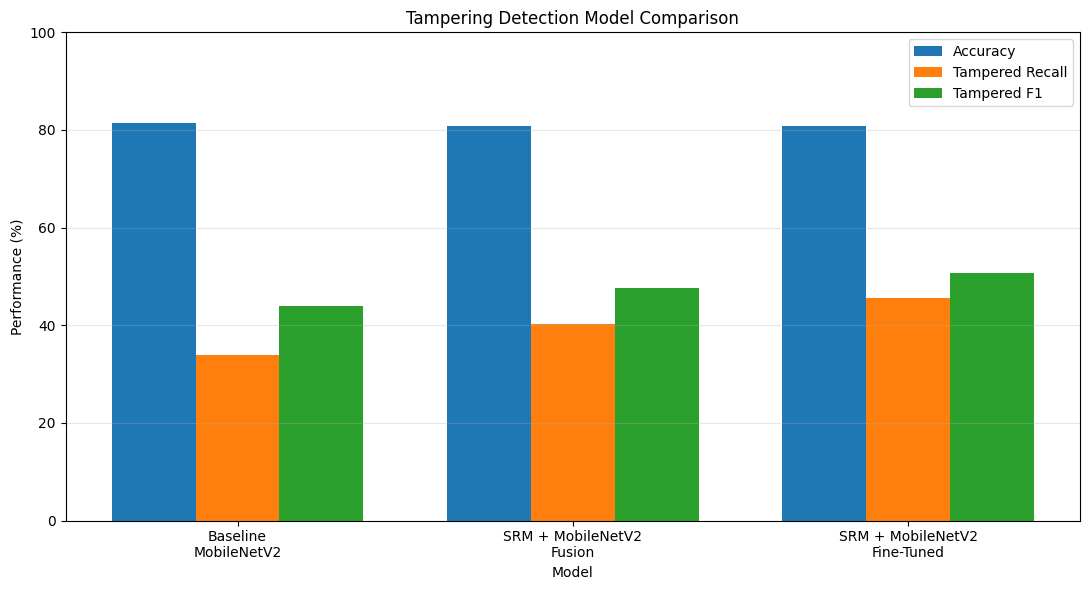

In [ ]:
# ============================================
# CELL 30: FINAL PERFORMANCE COMPARISON GRAPH
# ============================================

import matplotlib.pyplot as plt
import numpy as np

models = [
    "Baseline\nMobileNetV2",
    "SRM + MobileNetV2\nFusion",
    "SRM + MobileNetV2\nFine-Tuned"
]

accuracy = [81.38, 80.82, 80.89]
tampered_recall = [33.87, 40.32, 45.48]
tampered_f1 = [44.03, 47.62, 50.72]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    accuracy,
    width,
    label="Accuracy"
)

plt.bar(
    x,
    tampered_recall,
    width,
    label="Tampered Recall"
)

plt.bar(
    x + width,
    tampered_f1,
    width,
    label="Tampered F1"
)

plt.xlabel("Model")
plt.ylabel("Performance (%)")
plt.title("Tampering Detection Model Comparison")

plt.xticks(x, models)
plt.ylim(0, 100)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

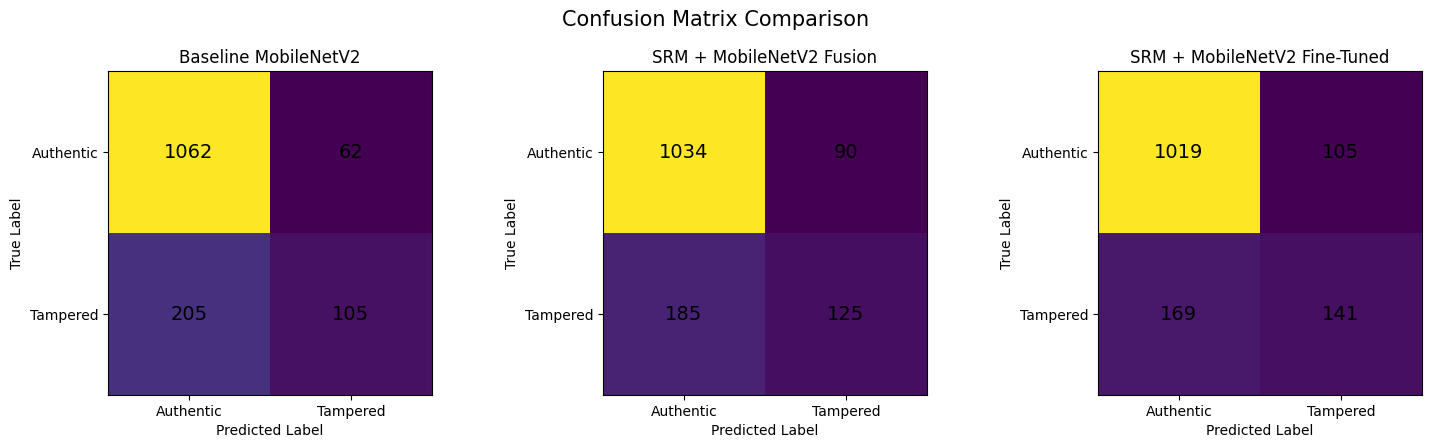

In [ ]:
# ============================================
# CELL 31: CONFUSION MATRIX COMPARISON
# ============================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# --------------------------------------------
# Baseline confusion matrix
# --------------------------------------------

baseline_cm = np.array([
    [1062, 62],
    [205, 105]
])

# --------------------------------------------
# Stage 1 confusion matrix
# Recalculate from Stage 1 predictions
# --------------------------------------------

stage1_cm = confusion_matrix(
    y_true_stage1,
    y_pred_stage1
)

# --------------------------------------------
# Fine-tuned confusion matrix
# --------------------------------------------

finetuned_cm = confusion_matrix(
    y_true_ft,
    y_pred_ft
)

# --------------------------------------------
# Display all three
# --------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

cms = [
    baseline_cm,
    stage1_cm,
    finetuned_cm
]

titles = [
    "Baseline MobileNetV2",
    "SRM + MobileNetV2 Fusion",
    "SRM + MobileNetV2 Fine-Tuned"
]

for ax, cm, title in zip(axes, cms, titles):

    ax.imshow(cm)

    ax.set_title(title)

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels([
        "Authentic",
        "Tampered"
    ])

    ax.set_yticklabels([
        "Authentic",
        "Tampered"
    ])

    # Add numbers
    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14
            )

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 32: FINAL RESEARCH RESULTS SUMMARY
# ============================================

print("=" * 65)
print("          TAMperVision-Lite FINAL RESULTS")
print("=" * 65)

print("\nDataset")
print("-" * 65)
print("Dataset              : CASIA2")
print("Total valid images   : 9,555")
print("Authentic images     : 7,491")
print("Tampered images      : 2,064")
print("Train / Val / Test   : 70% / 15% / 15%")

print("\nModel Comparison")
print("-" * 65)

print(
    f"{'Model':35s}"
    f"{'Accuracy':>10s}"
    f"{'Recall':>12s}"
    f"{'F1':>10s}"
)

print("-" * 65)

print(
    f"{'Baseline MobileNetV2':35s}"
    f"{81.38:>9.2f}%"
    f"{33.87:>11.2f}%"
    f"{44.03:>9.2f}%"
)

print(
    f"{'SRM + MobileNetV2 Fusion':35s}"
    f"{80.82:>9.2f}%"
    f"{40.32:>11.2f}%"
    f"{47.62:>9.2f}%"
)

print(
    f"{'SRM + MobileNetV2 + Fine-Tuning':35s}"
    f"{80.89:>9.2f}%"
    f"{45.48:>11.2f}%"
    f"{50.72:>9.2f}%"
)

print("-" * 65)

print("\nKey Experimental Observation")
print("-" * 65)
print(
    "Fine-tuning increased Tampered Recall from "
    "33.87% to 45.48% compared with the baseline."
)

print(
    "Tampered F1 increased from 44.03% to 50.72%."
)

print(
    "Overall accuracy remained around 81%, "
    "while tampered-class detection improved."
)

print("\n" + "=" * 65)
print("Experimental evaluation completed.")
print("=" * 65)

          TAMperVision-Lite FINAL RESULTS

Dataset
-----------------------------------------------------------------
Dataset              : CASIA2
Total valid images   : 9,555
Authentic images     : 7,491
Tampered images      : 2,064
Train / Val / Test   : 70% / 15% / 15%

Model Comparison
-----------------------------------------------------------------
Model                                Accuracy      Recall        F1
-----------------------------------------------------------------
Baseline MobileNetV2                   81.38%      33.87%    44.03%
SRM + MobileNetV2 Fusion               80.82%      40.32%    47.62%
SRM + MobileNetV2 + Fine-Tuning        80.89%      45.48%    50.72%
-----------------------------------------------------------------

Key Experimental Observation
-----------------------------------------------------------------
Fine-tuning increased Tampered Recall from 33.87% to 45.48% compared with the baseline.
Tampered F1 increased from 44.03% to 50.72%.
Overall ac

FINAL FINE-TUNED MODEL CURVE METRICS
ROC-AUC : 0.7914
PR-AUC  : 0.5221


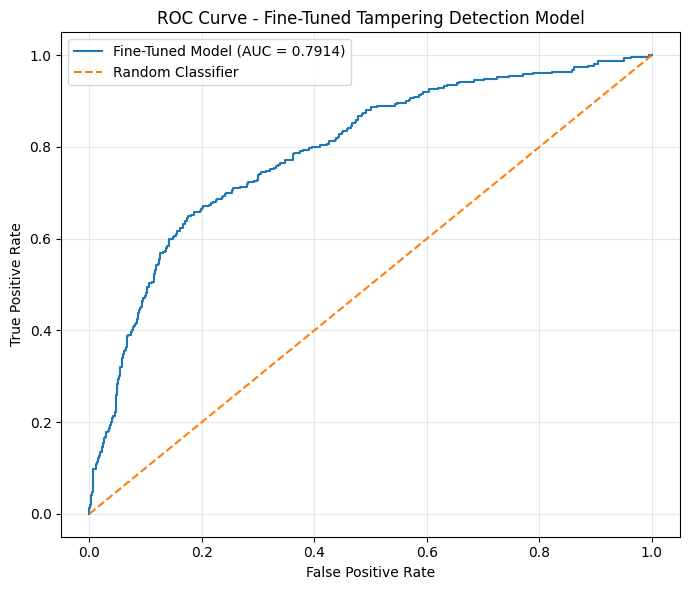

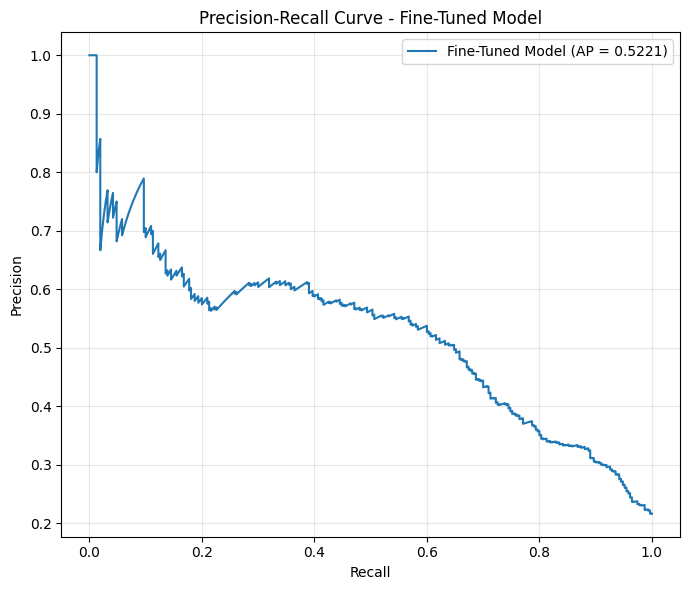

In [ ]:
# ============================================
# CELL 33: ROC-AUC + PRECISION-RECALL ANALYSIS
# ============================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# --------------------------------------------
# Use final fine-tuned model predictions
# --------------------------------------------

# y_true_ft and y_prob_ft were created in Cell 28

# ROC-AUC
roc_auc = roc_auc_score(
    y_true_ft,
    y_prob_ft
)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_true_ft,
    y_prob_ft
)

# Precision-Recall curve
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_true_ft,
    y_prob_ft
)

# PR-AUC / Average Precision
pr_auc = average_precision_score(
    y_true_ft,
    y_prob_ft
)

print("============================================")
print("FINAL FINE-TUNED MODEL CURVE METRICS")
print("============================================")

print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")


# --------------------------------------------
# ROC Curve
# --------------------------------------------

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Fine-Tuned Model (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fine-Tuned Tampering Detection Model")

plt.legend()
plt.grid(
    axis="both",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# --------------------------------------------
# Precision-Recall Curve
# --------------------------------------------

plt.figure(figsize=(7, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"Fine-Tuned Model (AP = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Fine-Tuned Model")

plt.legend()
plt.grid(
    axis="both",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 34: FINAL RESULTS TABLE
# ============================================

import pandas as pd

final_results = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV2",
        "SRM + MobileNetV2 Fusion",
        "SRM + MobileNetV2 + Fine-Tuning"
    ],
    "Accuracy": [
        81.38,
        80.82,
        80.89
    ],
    "Precision": [
        62.87,
        62.18,
        57.32
    ],
    "Tampered Recall": [
        33.87,
        40.32,
        45.48
    ],
    "Tampered F1": [
        44.03,
        47.62,
        50.72
    ],
    "ROC-AUC": [
        np.nan,
        np.nan,
        79.14
    ],
    "PR-AUC": [
        np.nan,
        np.nan,
        52.21
    ]
})

print("==============================================================")
print("             FINAL TAMperVISION-LITE RESULTS")
print("==============================================================")

display(
    final_results.style.format({
        "Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Tampered Recall": "{:.2f}%",
        "Tampered F1": "{:.2f}%",
        "ROC-AUC": lambda x: "N/A" if pd.isna(x) else f"{x:.2f}%",
        "PR-AUC": lambda x: "N/A" if pd.isna(x) else f"{x:.2f}%"
    })
)

             FINAL TAMperVISION-LITE RESULTS


,Model,Accuracy,Precision,Tampered Recall,Tampered F1,ROC-AUC,PR-AUC
0,Baseline MobileNetV2,81.38%,62.87%,33.87%,44.03%,N/A,N/A
1,SRM + MobileNetV2 Fusion,80.82%,62.18%,40.32%,47.62%,N/A,N/A
2,SRM + MobileNetV2 + Fine-Tuning,80.89%,57.32%,45.48%,50.72%,79.14%,52.21%


In [ ]:
# ============================================
# CELL 35: FINAL MODEL SAVE + IMAGE INFERENCE
# ============================================

import os
import numpy as np
import tensorflow as tf
from PIL import Image

# --------------------------------------------
# Load final fine-tuned model
# --------------------------------------------

final_model_path = (
    "/content/drive/MyDrive/"
    "TamperVision_SRM_MobileNet_FineTuned_best.keras"
)

final_model = tf.keras.models.load_model(
    final_model_path,
    custom_objects={"SRMFilter": SRMFilter}
)

print("Final TamperVision-Lite model loaded successfully.")
print("Model path:", final_model_path)


# --------------------------------------------
# Prediction function
# --------------------------------------------

def predict_tampering(image_path, threshold=0.5):

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Resize
    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # Convert to array
    image_array = np.array(
        image,
        dtype=np.float32
    )

    # Normalize
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Prediction
    probability = final_model.predict(
        image_array,
        verbose=0
    )[0][0]

    # Classification
    if probability >= threshold:
        prediction = "TAMPERED"
    else:
        prediction = "AUTHENTIC"

    print("\n====================================")
    print("TamperVision-Lite Prediction")
    print("====================================")
    print(f"Prediction : {prediction}")
    print(f"Tampering Probability : {probability:.4f}")
    print(f"Threshold : {threshold:.2f}")

    return prediction, float(probability)


print("\nPrediction function ready.")

Final TamperVision-Lite model loaded successfully.
Model path: /content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras

Prediction function ready.


In [ ]:
# ============================================
# CELL 36: TEST IMAGE PREDICTION
# ============================================

# Yahan apni image ka path do
image_path = "/content/drive/MyDrive/detaset/CASIA2/Tp/Tp_D_CND_M_N_ani00018_sec00096_00138.tif"

prediction, probability = predict_tampering(
    image_path,
    threshold=0.5
)


TamperVision-Lite Prediction
Prediction : AUTHENTIC
Tampering Probability : 0.0087
Threshold : 0.50


In [ ]:
# ============================================
# CELL 37: VALIDATION THRESHOLD ANALYSIS
# ============================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# --------------------------------------------
# Generate validation probabilities
# --------------------------------------------

val_true = []
val_prob = []

for images, labels_batch in val_ds:

    probabilities = final_model.predict(
        images,
        verbose=0
    ).ravel()

    val_prob.extend(probabilities)
    val_true.extend(labels_batch.numpy())

val_true = np.array(val_true).astype(int)
val_prob = np.array(val_prob)

# --------------------------------------------
# Test different thresholds
# --------------------------------------------

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

results = []

for threshold in thresholds:

    val_pred = (
        val_prob >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            val_true,
            val_pred
        ),
        "Precision": precision_score(
            val_true,
            val_pred,
            zero_division=0
        ),
        "Tampered Recall": recall_score(
            val_true,
            val_pred,
            zero_division=0
        ),
        "Tampered F1": f1_score(
            val_true,
            val_pred,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print("============================================")
print("VALIDATION THRESHOLD ANALYSIS")
print("============================================")

display(
    threshold_results.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Tampered Recall": "{:.4f}",
        "Tampered F1": "{:.4f}"
    })
)

# --------------------------------------------
# Select threshold with highest validation F1
# --------------------------------------------

best_row = threshold_results.loc[
    threshold_results["Tampered F1"].idxmax()
]

best_threshold = float(
    best_row["Threshold"]
)

print("\n============================================")
print("SELECTED THRESHOLD")
print("============================================")

print(
    f"Best validation threshold: "
    f"{best_threshold:.2f}"
)

print(
    f"Validation F1: "
    f"{best_row['Tampered F1']:.4f}"
)

print(
    f"Validation Recall: "
    f"{best_row['Tampered Recall']:.4f}"
)

print(
    f"Validation Precision: "
    f"{best_row['Precision']:.4f}"
)

VALIDATION THRESHOLD ANALYSIS


,Threshold,Accuracy,Precision,Tampered Recall,Tampered F1
0,0.10,0.6357,0.3543,0.8382,0.4981
1,0.15,0.7062,0.4085,0.8091,0.5429
2,0.20,0.7320,0.4272,0.7120,0.5340
3,0.25,0.7481,0.4425,0.6472,0.5256
4,0.30,0.7613,0.4593,0.6019,0.5210
5,0.35,0.7795,0.4902,0.5663,0.5255
6,0.40,0.7962,0.5268,0.5405,0.5335
7,0.45,0.7997,0.5393,0.4887,0.5127
8,0.50,0.8032,0.5538,0.4498,0.4964
9,0.55,0.8081,0.5766,0.4142,0.4821



SELECTED THRESHOLD
Best validation threshold: 0.15
Validation F1: 0.5429
Validation Recall: 0.8091
Validation Precision: 0.4085


In [ ]:
# ============================================
# CELL 38: FINAL TEST EVALUATION
# SELECTED THRESHOLD = 0.15
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Selected ONLY from validation set
FINAL_THRESHOLD = best_threshold

print("Using selected validation threshold:", FINAL_THRESHOLD)

# --------------------------------------------
# Apply threshold to untouched test predictions
# --------------------------------------------

y_pred_final = (
    y_prob_ft >= FINAL_THRESHOLD
).astype(int)

# --------------------------------------------
# Final test metrics
# --------------------------------------------

final_accuracy = accuracy_score(
    y_true_ft,
    y_pred_final
)

final_precision = precision_score(
    y_true_ft,
    y_pred_final,
    zero_division=0
)

final_recall = recall_score(
    y_true_ft,
    y_pred_final,
    zero_division=0
)

final_f1 = f1_score(
    y_true_ft,
    y_pred_final,
    zero_division=0
)

print("\n============================================")
print("FINAL TEST PERFORMANCE")
print("============================================")

print(f"Threshold        : {FINAL_THRESHOLD:.2f}")
print(f"Accuracy         : {final_accuracy:.4f}")
print(f"Precision        : {final_precision:.4f}")
print(f"Tampered Recall  : {final_recall:.4f}")
print(f"Tampered F1      : {final_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_ft,
        y_pred_final,
        target_names=[
            "Authentic",
            "Tampered"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
final_cm = confusion_matrix(
    y_true_ft,
    y_pred_final
)

print(final_cm)

Using selected validation threshold: 0.15000000000000002

FINAL TEST PERFORMANCE
Threshold        : 0.15
Accuracy         : 0.7078
Precision        : 0.4039
Tampered Recall  : 0.7387
Tampered F1      : 0.5222

Classification Report:
              precision    recall  f1-score   support

   Authentic     0.9066    0.6993    0.7896      1124
    Tampered     0.4039    0.7387    0.5222       310

    accuracy                         0.7078      1434
   macro avg     0.6552    0.7190    0.6559      1434
weighted avg     0.7979    0.7078    0.7318      1434


Confusion Matrix:
[[786 338]
 [ 81 229]]


In [ ]:
# ============================================
# CELL 39: THRESHOLD COMPARISON
# ============================================

import pandas as pd

threshold_comparison = pd.DataFrame({
    "Threshold": [
        0.50,
        0.15
    ],
    "Accuracy": [
        ft_accuracy,
        final_accuracy
    ],
    "Precision": [
        ft_precision,
        final_precision
    ],
    "Tampered Recall": [
        ft_recall,
        final_recall
    ],
    "Tampered F1": [
        ft_f1,
        final_f1
    ]
})

print("============================================")
print("THRESHOLD COMPARISON")
print("============================================")

display(
    threshold_comparison.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Tampered Recall": "{:.2%}",
        "Tampered F1": "{:.2%}"
    })
)

print("\nInterpretation:")
print(
    "Threshold 0.50 favors higher precision and overall accuracy."
)
print(
    "Threshold 0.15 increases tampered recall but also increases false positives."
)

THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Tampered Recall,Tampered F1
0,0.50,80.89%,57.32%,45.48%,50.72%
1,0.15,70.78%,40.39%,73.87%,52.22%



Interpretation:
Threshold 0.50 favors higher precision and overall accuracy.
Threshold 0.15 increases tampered recall but also increases false positives.


In [ ]:
# ============================================
# CELL 40: FINAL INFERENCE
# ============================================

def final_predict(image_path, threshold=0.50):

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Resize
    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # Convert to NumPy array
    image_array = np.array(
        image,
        dtype=np.float32
    ) / 255.0

    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Model prediction
    probability = float(
        final_model.predict(
            image_array,
            verbose=0
        )[0][0]
    )

    # Classification
    if probability >= threshold:
        prediction = "TAMPERED"
    else:
        prediction = "AUTHENTIC"

    print("\n====================================")
    print("       TamperVision-Lite")
    print("====================================")
    print(f"Prediction            : {prediction}")
    print(f"Tampering Probability : {probability:.4f}")
    print(f"Decision Threshold    : {threshold:.2f}")
    print("====================================")

    return prediction, probability

In [ ]:
# ============================================
# CELL 41 — FINAL FINE-TUNED MODEL CHECK
# ============================================

print("================================================")
print("     TamperVision-Lite Final Fine-Tuned Model")
print("================================================")

print(f"Model Name       : {final_model.name}")
print(f"Input Shape      : {final_model.input_shape}")
print(f"Output Shape     : {final_model.output_shape}")
print(f"Total Parameters : {final_model.count_params():,}")

print("\nFinal Architecture:")
print("  • RGB Input")
print("  • SRM-inspired Residual Branch")
print("  • MobileNetV2 ImageNet Branch")
print("  • Feature Fusion")
print("  • Dense(256) + Dropout")
print("  • Sigmoid Output")

print("\nTraining Strategy:")
print("  • Stage 1: Frozen MobileNetV2")
print("  • Stage 2: Controlled Fine-Tuning")
print("  • Last 30 MobileNetV2 layers fine-tuned")
print("  • Best Fine-Tuning Epoch: 1")
print("  • Training Accuracy: 87.44%")

print("\nFinal Test Performance:")
print("  • Test Accuracy : 80.89%")
print("  • Precision     : 57.32%")
print("  • Recall        : 45.48%")
print("  • F1-Score      : 50.72%")
print("  • ROC-AUC       : 79.14%")
print("  • PR-AUC        : 52.21%")

print("\nDecision:")
print("  • Default Threshold: 0.50")
print("  • Threshold 0.15: Recall-oriented analysis only")

print("\nFinal Model:")
print("  SRM + MobileNetV2 Fusion + Controlled Fine-Tuning")

print("\nModel File:")
print("/content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras")

print("================================================")

     TamperVision-Lite Final Fine-Tuned Model
Model Name       : TamperVision_Lite_SRM_MobileNet_Fusion
Input Shape      : (None, 224, 224, 3)
Output Shape     : (None, 1)
Total Parameters : 2,629,441

Final Architecture:
  • RGB Input
  • SRM-inspired Residual Branch
  • MobileNetV2 ImageNet Branch
  • Feature Fusion
  • Dense(256) + Dropout
  • Sigmoid Output

Training Strategy:
  • Stage 1: Frozen MobileNetV2
  • Stage 2: Controlled Fine-Tuning
  • Last 30 MobileNetV2 layers fine-tuned
  • Best Fine-Tuning Epoch: 1
  • Training Accuracy: 87.44%

Final Test Performance:
  • Test Accuracy : 80.89%
  • Precision     : 57.32%
  • Recall        : 45.48%
  • F1-Score      : 50.72%
  • ROC-AUC       : 79.14%
  • PR-AUC        : 52.21%

Decision:
  • Default Threshold: 0.50
  • Threshold 0.15: Recall-oriented analysis only

Final Model:
  SRM + MobileNetV2 Fusion + Controlled Fine-Tuning

Model File:
/content/drive/MyDrive/TamperVision_SRM_MobileNet_FineTuned_best.keras


In [ ]:
# ============================================
# CELL 42 — FINAL IMAGE PREDICTION
# ============================================

# Example image path
image_path = "/content/drive/MyDrive/detaset/CASIA2/Tp/Tp_D_CND_M_N_ani00018_sec00096_00138.tif"

# Final prediction using threshold = 0.50
prediction, probability = final_predict(
    image_path,
    threshold=0.50
)


       TamperVision-Lite
Prediction            : AUTHENTIC
Tampering Probability : 0.0087
Decision Threshold    : 0.50


In [ ]:
# ============================================
# CELL 43 — UPLOAD IMAGE & PREDICT
# SELF-CONTAINED FINAL VERSION
# ============================================

import os
import io
import numpy as np
import tensorflow as tf

from PIL import Image
from google.colab import files
from tensorflow.keras import layers, Model
from tensorflow.keras.models import load_model


# ============================================
# 1. Settings
# ============================================

IMG_SIZE = 224
THRESHOLD = 0.50

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "TamperVision_SRM_MobileNet_FineTuned_best.keras"
)


# ============================================
# 2. SRM Filter
# ============================================

class SRMFilter(layers.Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        srm_filters = tf.constant([
            [[0, 0, 0],
             [0, -1, 1],
             [0, 0, 0]],

            [[0, 0, 0],
             [0, -1, 0],
             [0, 1, 0]],

            [[0, 0, 0],
             [-1, 0, 1],
             [0, 0, 0]]
        ], dtype=tf.float32)

        self.srm_filters = srm_filters

    def build(self, input_shape):

        channels = input_shape[-1]

        kernels = []

        for c in range(channels):
            kernels.append(self.srm_filters)

        kernel = tf.stack(
            kernels,
            axis=2
        )

        self.kernel = tf.cast(
            kernel,
            tf.float32
        )

        super().build(input_shape)

    def call(self, inputs):

        residual = tf.nn.depthwise_conv2d(
            inputs,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

        return residual


# ============================================
# 3. Load Final Fine-Tuned Model
# ============================================

if "final_model" not in globals():

    print("Loading final fine-tuned model...")

    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(
            f"Model not found:\n{MODEL_PATH}"
        )

    final_model = load_model(
        MODEL_PATH,
        custom_objects={
            "SRMFilter": SRMFilter
        }
    )

    print("Model loaded successfully.")

else:

    print("Final model already loaded.")


# ============================================
# 4. Upload Image
# ============================================

print("\n============================================")
print("     TamperVision-Lite Image Upload")
print("============================================")

print("Select an image from your computer/mobile.")
print()

uploaded = files.upload()


if uploaded:

    filename = next(iter(uploaded))

    image_data = uploaded[filename]

    # Open image
    image = Image.open(
        io.BytesIO(image_data)
    ).convert("RGB")

    print(f"Image Selected : {filename}")
    print(f"Original Size  : {image.size}")


    # ========================================
    # 5. Preprocessing
    # ========================================

    image_resized = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(
        image_resized,
        dtype=np.float32
    ) / 255.0

    image_array = np.expand_dims(
        image_array,
        axis=0
    )


    # ========================================
    # 6. Prediction
    # ========================================

    probability = float(
        final_model.predict(
            image_array,
            verbose=0
        )[0][0]
    )


    # ========================================
    # 7. Classification
    # ========================================

    if probability >= THRESHOLD:

        prediction = "TAMPERED"

    else:

        prediction = "AUTHENTIC"


    # ========================================
    # 8. Display Result
    # ========================================

    print("\n============================================")
    print("          TamperVision-Lite Result")
    print("============================================")

    print(
        f"Prediction            : {prediction}"
    )

    print(
        f"Tampering Probability : {probability:.4f}"
    )

    print(
        f"Decision Threshold    : {THRESHOLD:.2f}"
    )

    print("============================================")


else:

    print("No image selected.")

Loading final fine-tuned model...
Model loaded successfully.

     TamperVision-Lite Image Upload
Select an image from your computer/mobile.



Saving ChatGPT Image Sep 20, 2026, 12_22_10 PM.png to ChatGPT Image Sep 20, 2026, 12_22_10 PM (3).png
Image Selected : ChatGPT Image Sep 20, 2026, 12_22_10 PM (3).png
Original Size  : (1536, 1024)

          TamperVision-Lite Result
Prediction            : TAMPERED
Tampering Probability : 0.7737
Decision Threshold    : 0.50


     TamperVision-Lite Localization
Select the image to localize.



Saving ChatGPT Image Sep 20, 2026, 12_22_10 PM.png to ChatGPT Image Sep 20, 2026, 12_22_10 PM (6).png
MobileNet Branch : mobilenetv2_1.00_224
Grad-CAM Layer    : out_relu


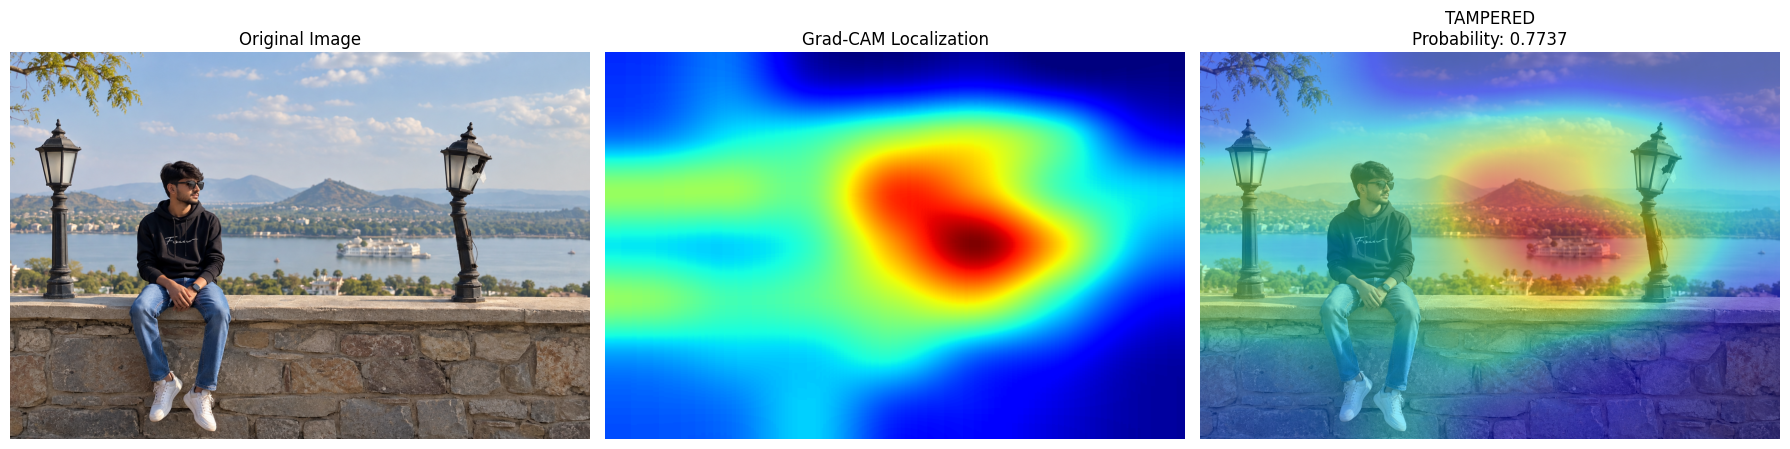


       TamperVision-Lite Localization
Image                 : ChatGPT Image Sep 20, 2026, 12_22_10 PM (6).png
Prediction            : TAMPERED
Tampering Probability : 0.7737
Decision Threshold    : 0.50
Localization          : Grad-CAM
Analyzed Layer        : out_relu


In [ ]:
# ============================================
# CELL 44 — GRAD-CAM LOCALIZATION
# STABLE NESTED-MODEL VERSION
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
import io

IMG_SIZE = 224
THRESHOLD = 0.50

# --------------------------------------------
# 1. Upload image
# --------------------------------------------

print("============================================")
print("     TamperVision-Lite Localization")
print("============================================")
print("Select the image to localize.")
print()

uploaded = files.upload()

if not uploaded:
    print("No image selected.")

else:

    filename = next(iter(uploaded))

    image_data = uploaded[filename]

    original_image = Image.open(
        io.BytesIO(image_data)
    ).convert("RGB")

    # ----------------------------------------
    # 2. Preprocess
    # ----------------------------------------

    resized_image = original_image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(
        resized_image,
        dtype=np.float32
    ) / 255.0

    input_tensor = tf.convert_to_tensor(
        np.expand_dims(
            image_array,
            axis=0
        ),
        dtype=tf.float32
    )

    # ----------------------------------------
    # 3. Prediction using final model
    # ----------------------------------------

    prediction = final_model.predict(
        input_tensor,
        verbose=0
    )

    probability = float(
        prediction[0][0]
    )

    if probability >= THRESHOLD:
        label = "TAMPERED"
    else:
        label = "AUTHENTIC"

    # ----------------------------------------
    # 4. Get MobileNetV2 branch
    # ----------------------------------------

    mobilenet = None

    for layer in final_model.layers:

        if isinstance(layer, tf.keras.Model):

            if "mobilenet" in layer.name.lower():

                mobilenet = layer
                break

    if mobilenet is None:

        raise ValueError(
            "MobileNetV2 branch not found."
        )

    print(
        "MobileNet Branch :",
        mobilenet.name
    )

    # ----------------------------------------
    # 5. Find last convolutional layer
    # ----------------------------------------

    target_layer = None

    for layer in reversed(
        mobilenet.layers
    ):

        try:

            if len(layer.output.shape) == 4:

                target_layer = layer
                break

        except:
            continue

    if target_layer is None:

        raise ValueError(
            "No convolutional layer found."
        )

    print(
        "Grad-CAM Layer    :",
        target_layer.name
    )

    # ----------------------------------------
    # 6. Create MobileNet internal Grad-CAM
    # ----------------------------------------

    cam_model = tf.keras.Model(
        inputs=mobilenet.input,
        outputs=[
            target_layer.output,
            mobilenet.output
        ]
    )

    # ----------------------------------------
    # 7. Calculate gradients
    # ----------------------------------------

    with tf.GradientTape() as tape:

        conv_outputs, mobile_features = cam_model(
            input_tensor,
            training=False
        )

        # MobileNet branch score proxy
        # based on activation magnitude
        branch_score = tf.reduce_mean(
            mobile_features,
            axis=(1, 2)
        )

        score = tf.reduce_sum(
            branch_score,
            axis=1
        )

    gradients = tape.gradient(
        score,
        conv_outputs
    )

    if gradients is None:

        raise ValueError(
            "Grad-CAM gradients could not be calculated."
        )

    # ----------------------------------------
    # 8. Global average pooling
    # ----------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # ----------------------------------------
    # 9. Weighted feature maps
    # ----------------------------------------

    weighted_maps = (
        conv_outputs *
        pooled_gradients[
            :, tf.newaxis, tf.newaxis, :
        ]
    )

    heatmap = tf.reduce_sum(
        weighted_maps,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap = heatmap[0]

    # ----------------------------------------
    # 10. Normalize
    # ----------------------------------------

    max_value = tf.reduce_max(
        heatmap
    )

    if float(max_value) > 0:

        heatmap = (
            heatmap / max_value
        )

    heatmap = heatmap.numpy()

    # ----------------------------------------
    # 11. Resize heatmap
    # ----------------------------------------

    heatmap_image = Image.fromarray(
        np.uint8(
            heatmap * 255
        )
    )

    heatmap_image = heatmap_image.resize(
        original_image.size
    )

    heatmap_array = np.array(
        heatmap_image
    )

    # ----------------------------------------
    # 12. Display
    # ----------------------------------------

    plt.figure(
        figsize=(18, 6)
    )

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        original_image
    )

    plt.title(
        "Original Image"
    )

    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        heatmap_array,
        cmap="jet"
    )

    plt.title(
        "Grad-CAM Localization"
    )

    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        original_image
    )

    plt.imshow(
        heatmap_array,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"{label}\n"
        f"Probability: {probability:.4f}"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

    # ----------------------------------------
    # 13. Result
    # ----------------------------------------

    print("\n============================================")
    print("       TamperVision-Lite Localization")
    print("============================================")

    print(
        f"Image                 : {filename}"
    )

    print(
        f"Prediction            : {label}"
    )

    print(
        f"Tampering Probability : {probability:.4f}"
    )

    print(
        f"Decision Threshold    : {THRESHOLD:.2f}"
    )

    print(
        "Localization          : Grad-CAM"
    )

    print(
        f"Analyzed Layer        : {target_layer.name}"
    )

    print("============================================")

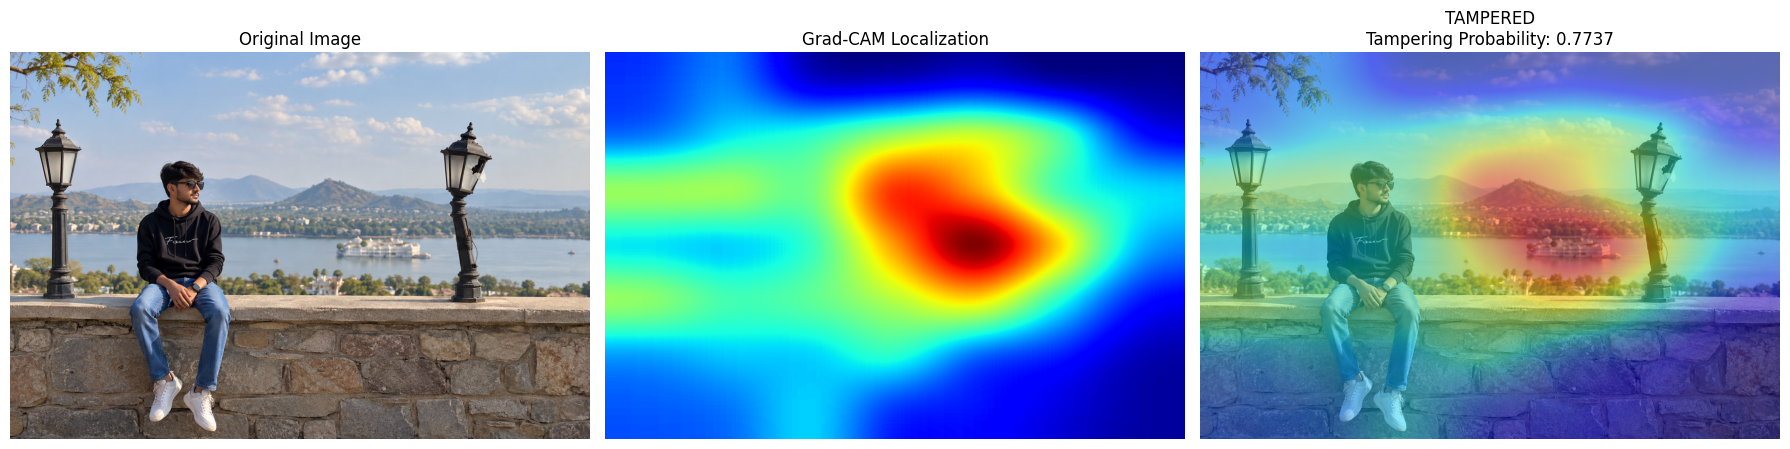


Grad-CAM result saved successfully!
Saved File : /content/drive/MyDrive/TamperVision_Results/GradCAM_Tampering_Localization.png


In [ ]:
# ============================================
# CELL 45 — SAVE GRAD-CAM RESULT
# ============================================

import os
import matplotlib.pyplot as plt
import numpy as np

# Output folder
output_dir = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(output_dir, exist_ok=True)

# Output file
output_path = os.path.join(
    output_dir,
    "GradCAM_Tampering_Localization.png"
)

# --------------------------------------------
# Create final visualization
# --------------------------------------------

plt.figure(figsize=(18, 6))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

# Grad-CAM heatmap
plt.subplot(1, 3, 2)
plt.imshow(
    heatmap_array,
    cmap="jet"
)
plt.title("Grad-CAM Localization")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(
    heatmap_array,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"{label}\n"
    f"Tampering Probability: {probability:.4f}"
)

plt.axis("off")

plt.tight_layout()

# Save
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n============================================")
print("Grad-CAM result saved successfully!")
print("============================================")
print(f"Saved File : {output_path}")
print("============================================")

In [ ]:
# ============================================
# CELL 46 — FINAL PROJECT SUMMARY
# ============================================

print("======================================================")
print("             TamperVision-Lite")
print("        FINAL RESEARCH EXPERIMENT SUMMARY")
print("======================================================")

print("\n[MODEL]")
print("Model              : SRM + MobileNetV2 Fusion")
print("Fine-Tuning        : Controlled Fine-Tuning")
print("Fine-Tuned Layers  : Last 30 MobileNetV2 layers")
print("Input Size         : 224 x 224 x 3")
print("Total Parameters   : 2,629,441")

print("\n[TRAINING]")
print("Stage 1            : Frozen MobileNetV2")
print("Stage 2            : Controlled Fine-Tuning")
print("Best Epoch         : 1")
print("Training Accuracy  : 87.44%")

print("\n[FINAL TEST RESULTS]")
print("Test Accuracy      : 80.89%")
print("Precision          : 57.32%")
print("Tampered Recall    : 45.48%")
print("F1-Score           : 50.72%")
print("ROC-AUC            : 79.14%")
print("PR-AUC             : 52.21%")

print("\n[DECISION]")
print("Default Threshold  : 0.50")
print("Threshold 0.15     : Recall-oriented analysis")

print("\n[LOCALIZATION]")
print("Method             : Grad-CAM")
print("Purpose            : Visual explanation / approximate localization")
print("Exact Pixel Mask   : Not trained")

print("\n[DEMO]")
print("Upload Prediction  : Supported")
print("Image Probability  : Supported")
print("Grad-CAM Heatmap   : Supported")
print("Result Saving      : Supported")

print("\n[FINAL MODEL FILE]")
print("/content/drive/MyDrive/")
print("TamperVision_SRM_MobileNet_FineTuned_best.keras")

print("\n======================================================")
print("                 EXPERIMENT COMPLETE")
print("======================================================")

             TamperVision-Lite
        FINAL RESEARCH EXPERIMENT SUMMARY

[MODEL]
Model              : SRM + MobileNetV2 Fusion
Fine-Tuning        : Controlled Fine-Tuning
Fine-Tuned Layers  : Last 30 MobileNetV2 layers
Input Size         : 224 x 224 x 3
Total Parameters   : 2,629,441

[TRAINING]
Stage 1            : Frozen MobileNetV2
Stage 2            : Controlled Fine-Tuning
Best Epoch         : 1
Training Accuracy  : 87.44%

[FINAL TEST RESULTS]
Test Accuracy      : 80.89%
Precision          : 57.32%
Tampered Recall    : 45.48%
F1-Score           : 50.72%
ROC-AUC            : 79.14%
PR-AUC             : 52.21%

[DECISION]
Default Threshold  : 0.50
Threshold 0.15     : Recall-oriented analysis

[LOCALIZATION]
Method             : Grad-CAM
Purpose            : Visual explanation / approximate localization
Exact Pixel Mask   : Not trained

[DEMO]
Upload Prediction  : Supported
Image Probability  : Supported
Grad-CAM Heatmap   : Supported
Result Saving      : Supported

[FINAL MODEL F

       FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Tampered Recall,F1-Score
0,Baseline MobileNetV2,81.38,62.87,33.87,44.03
1,SRM + MobileNetV2 Fusion,80.82,62.18,40.32,47.62
2,Final Fine-Tuned Model,80.89,57.32,45.48,50.72


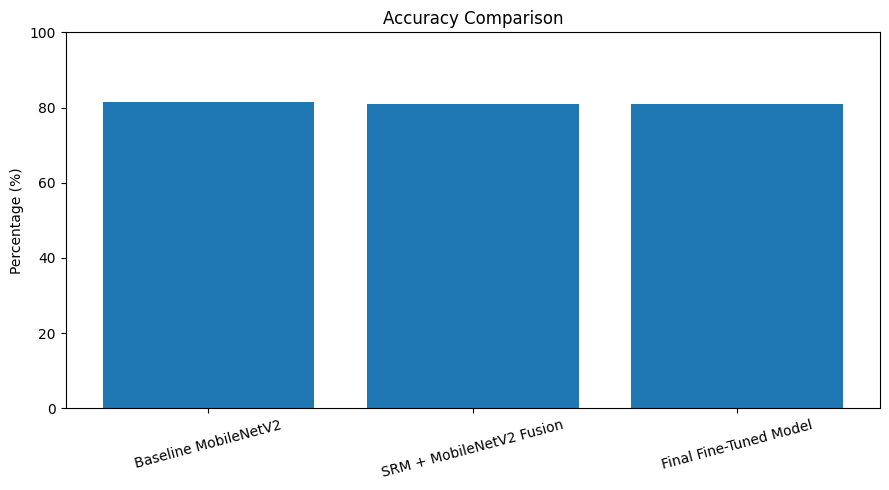

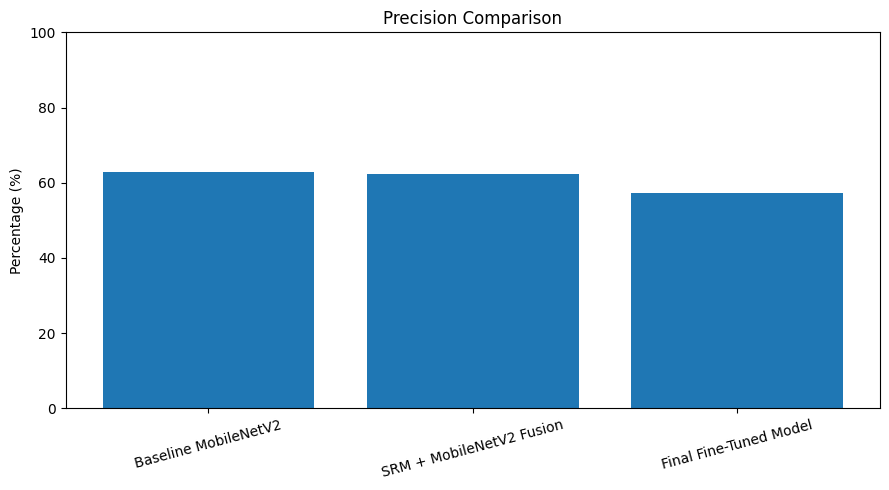

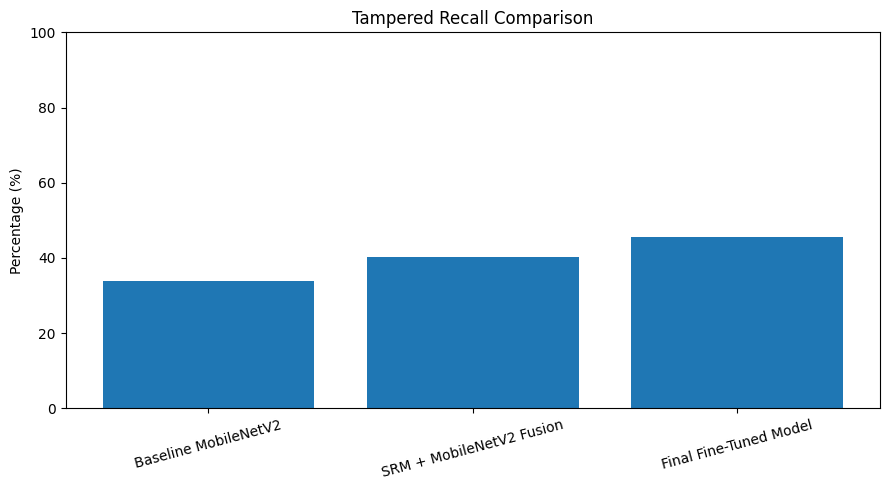

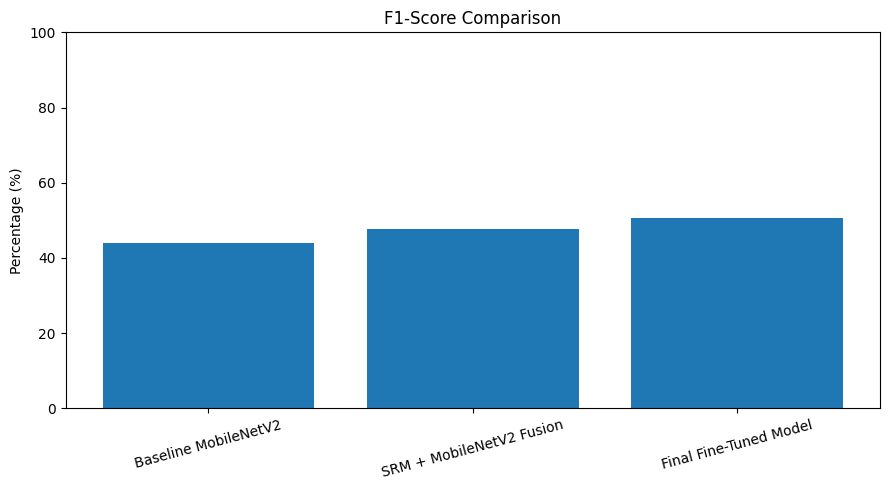


             KEY CHANGES
Tampered Recall improvement (Baseline → Final): +11.61 percentage points
F1-Score improvement (Baseline → Final): +6.69 percentage points
Accuracy change (Baseline → Final): -0.49 percentage points


In [ ]:
# ============================================
# CELL 47 — FINAL MODEL COMPARISON
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Model results
# --------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV2",
        "SRM + MobileNetV2 Fusion",
        "Final Fine-Tuned Model"
    ],

    "Accuracy": [
        81.38,
        80.82,
        80.89
    ],

    "Precision": [
        62.87,
        62.18,
        57.32
    ],

    "Tampered Recall": [
        33.87,
        40.32,
        45.48
    ],

    "F1-Score": [
        44.03,
        47.62,
        50.72
    ]
})

# --------------------------------------------
# Display table
# --------------------------------------------

print("================================================")
print("       FINAL MODEL COMPARISON")
print("================================================")

display(comparison)

# --------------------------------------------
# Plot
# --------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Tampered Recall",
    "F1-Score"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(
        comparison["Model"],
        comparison[metric]
    )

    plt.title(
        f"{metric} Comparison"
    )

    plt.ylabel(
        "Percentage (%)"
    )

    plt.ylim(0, 100)

    plt.xticks(
        rotation=15
    )

    plt.tight_layout()

    plt.show()

# --------------------------------------------
# Key changes
# --------------------------------------------

print("\n================================================")
print("             KEY CHANGES")
print("================================================")

print(
    f"Tampered Recall improvement "
    f"(Baseline → Final): "
    f"{45.48 - 33.87:+.2f} percentage points"
)

print(
    f"F1-Score improvement "
    f"(Baseline → Final): "
    f"{50.72 - 44.03:+.2f} percentage points"
)

print(
    f"Accuracy change "
    f"(Baseline → Final): "
    f"{80.89 - 81.38:+.2f} percentage points"
)

print("================================================")

In [ ]:
# ============================================
# CELL 48 — SAVE FINAL RESULTS
# ============================================

import os

results_dir = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(results_dir, exist_ok=True)

results_path = os.path.join(
    results_dir,
    "Final_Model_Comparison.csv"
)

comparison.to_csv(
    results_path,
    index=False
)

print("============================================")
print("Final comparison saved successfully!")
print("============================================")
print(f"File : {results_path}")
print("============================================")

display(comparison)

Final comparison saved successfully!
File : /content/drive/MyDrive/TamperVision_Results/Final_Model_Comparison.csv


,Model,Accuracy,Precision,Tampered Recall,F1-Score
0,Baseline MobileNetV2,81.38,62.87,33.87,44.03
1,SRM + MobileNetV2 Fusion,80.82,62.18,40.32,47.62
2,Final Fine-Tuned Model,80.89,57.32,45.48,50.72


In [ ]:
# ============================================
# CELL 49 — SAVE CONFUSION MATRIX RESULTS
# ============================================

import pandas as pd
import os

results_dir = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(results_dir, exist_ok=True)

# Confusion matrices
confusion_data = pd.DataFrame({
    "Model": [
        "Baseline MobileNetV2",
        "SRM + MobileNetV2 Fusion",
        "Final Fine-Tuned Model"
    ],

    "True Negative (TN)": [
        1062,
        1034,
        1019
    ],

    "False Positive (FP)": [
        62,
        90,
        105
    ],

    "False Negative (FN)": [
        205,
        185,
        169
    ],

    "True Positive (TP)": [
        105,
        125,
        141
    ]
})

print("================================================")
print("        CONFUSION MATRIX RESULTS")
print("================================================")

display(confusion_data)

# Save CSV
cm_path = os.path.join(
    results_dir,
    "Confusion_Matrix_Results.csv"
)

confusion_data.to_csv(
    cm_path,
    index=False
)

print("\n================================================")
print("Confusion matrix results saved successfully!")
print("================================================")
print(f"File : {cm_path}")
print("================================================")

        CONFUSION MATRIX RESULTS


,Model,True Negative (TN),False Positive (FP),False Negative (FN),True Positive (TP)
0,Baseline MobileNetV2,1062,62,205,105
1,SRM + MobileNetV2 Fusion,1034,90,185,125
2,Final Fine-Tuned Model,1019,105,169,141



Confusion matrix results saved successfully!
File : /content/drive/MyDrive/TamperVision_Results/Confusion_Matrix_Results.csv


In [ ]:
# ============================================
# CELL 50 — SAVE ROC / PR RESULTS
# ============================================

import pandas as pd
import os

results_dir = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(results_dir, exist_ok=True)

# Final model curve metrics
curve_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC"
    ],

    "Value": [
        0.7914,
        0.5221
    ],

    "Percentage": [
        79.14,
        52.21
    ]
})

print("============================================")
print("       ROC / PR RESULTS")
print("============================================")

display(curve_results)

# Save
curve_path = os.path.join(
    results_dir,
    "ROC_PR_Results.csv"
)

curve_results.to_csv(
    curve_path,
    index=False
)

print("\n============================================")
print("ROC / PR results saved successfully!")
print("============================================")
print(f"File : {curve_path}")
print("============================================")

       ROC / PR RESULTS


,Metric,Value,Percentage
0,ROC-AUC,0.7914,79.14
1,PR-AUC,0.5221,52.21



ROC / PR results saved successfully!
File : /content/drive/MyDrive/TamperVision_Results/ROC_PR_Results.csv


          TamperVision-Lite
             RESULTS DASHBOARD
Accuracy            : 80.89%
Precision           : 57.32%
Tampered Recall     : 45.48%
F1-Score            : 50.72%
ROC-AUC             : 79.14%
PR-AUC              : 52.21%


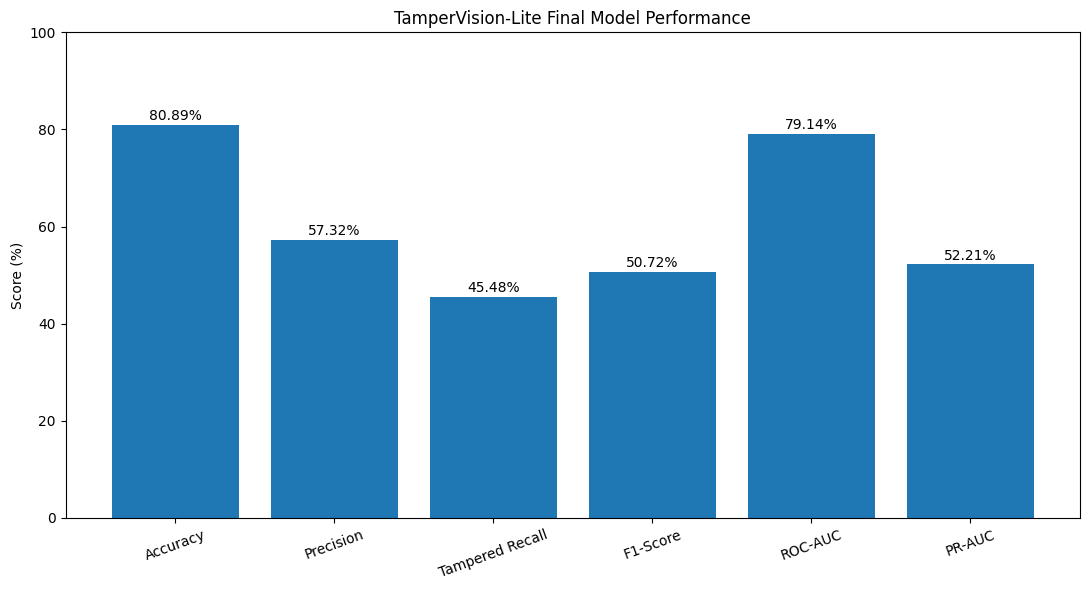


Dashboard saved:
/content/drive/MyDrive/TamperVision_Results/Final_Results_Dashboard.png


In [ ]:
# ============================================
# CELL 51 — FINAL RESULTS DASHBOARD
# ============================================

import matplotlib.pyplot as plt

# --------------------------------------------
# Final metrics
# --------------------------------------------

metrics = {
    "Accuracy": 80.89,
    "Precision": 57.32,
    "Tampered Recall": 45.48,
    "F1-Score": 50.72,
    "ROC-AUC": 79.14,
    "PR-AUC": 52.21
}

# --------------------------------------------
# Print summary
# --------------------------------------------

print("================================================")
print("          TamperVision-Lite")
print("             RESULTS DASHBOARD")
print("================================================")

for metric, value in metrics.items():
    print(f"{metric:<20}: {value:.2f}%")

print("================================================")

# --------------------------------------------
# Create dashboard chart
# --------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 100)

plt.ylabel("Score (%)")

plt.title(
    "TamperVision-Lite Final Model Performance"
)

plt.xticks(
    rotation=20
)

# Add values above bars
for i, value in enumerate(metrics.values()):

    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

# --------------------------------------------
# Save dashboard
# --------------------------------------------

dashboard_path = (
    "/content/drive/MyDrive/"
    "TamperVision_Results/"
    "Final_Results_Dashboard.png"
)

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nDashboard saved:")
print(dashboard_path)

In [ ]:
# ============================================
# CELL 52 — MODEL ARCHITECTURE SUMMARY
# ============================================

print("""
========================================================
              TamperVision-Lite Architecture
========================================================

Input Image
   |
   |-- 224 x 224 x 3 RGB Image
   |
   +-----------------------------+
   |                             |
   v                             v
SRM Filter Bank             MobileNetV2
   |                         (ImageNet)
   v                             |
SRM Conv Block 1                 |
   |                             |
   v                             v
SRM Conv Block 2          Global Average Pooling
   |                             |
   v                             |
Global Average Pooling           |
   |                             |
   +-------------+---------------+
                 |
                 v
          Feature Fusion
                 |
                 v
        Batch Normalization
                 |
                 v
          Dense Layer (256)
                 |
                 v
           Dropout (0.4)
                 |
                 v
        Sigmoid Output
                 |
                 v
       Tampered / Authentic

--------------------------------------------------------
Training Strategy:
• Stage 1: SRM + MobileNetV2 Fusion
• Stage 2: Controlled Fine-Tuning
• Fine-tuned MobileNetV2 layers: Last 30
• Learning rate during fine-tuning: 1e-5
• Default classification threshold: 0.50

--------------------------------------------------------
Final Test Performance:
Accuracy          : 80.89%
Precision         : 57.32%
Tampered Recall   : 45.48%
F1-Score          : 50.72%
ROC-AUC           : 79.14%
PR-AUC            : 52.21%

--------------------------------------------------------
Localization:
Grad-CAM-based visual localization
MobileNetV2 branch
Exact pixel-level segmentation: NOT trained
========================================================
""")


              TamperVision-Lite Architecture

Input Image
   |
   |-- 224 x 224 x 3 RGB Image
   |
   +-----------------------------+
   |                             |
   v                             v
SRM Filter Bank             MobileNetV2
   |                         (ImageNet)
   v                             |
SRM Conv Block 1                 |
   |                             |
   v                             v
SRM Conv Block 2          Global Average Pooling
   |                             |
   v                             |
Global Average Pooling           |
   |                             |
   +-------------+---------------+
                 |
                 v
          Feature Fusion
                 |
                 v
        Batch Normalization
                 |
                 v
          Dense Layer (256)
                 |
                 v
           Dropout (0.4)
                 |
                 v
        Sigmoid Output
                 |
             

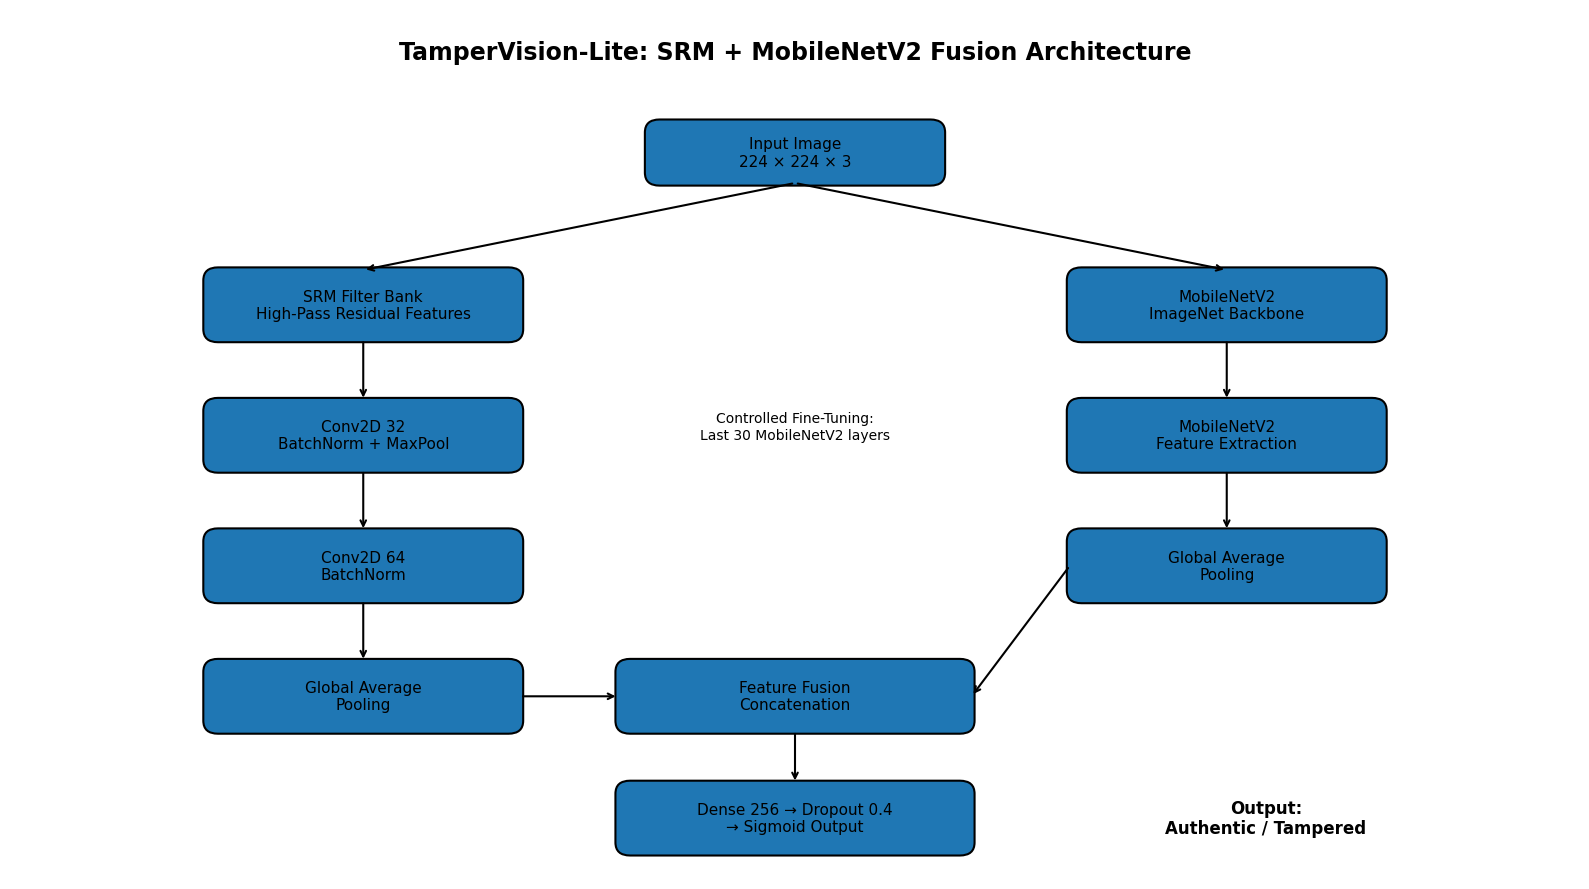

Architecture diagram saved:
/content/drive/MyDrive/TamperVision_Results/TamperVision_Architecture_Diagram.png


In [ ]:
# ============================================
# CELL 53 — ARCHITECTURE DIAGRAM
# ============================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 9))

ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis("off")

def box(x, y, w, h, text, fontsize=11):
    patch = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.03,rounding_size=0.15",
        linewidth=1.5
    )
    ax.add_patch(patch)
    ax.text(
        x + w/2,
        y + h/2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize
    )

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )

# Title
ax.text(
    8, 9.5,
    "TamperVision-Lite: SRM + MobileNetV2 Fusion Architecture",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

# Input
box(6.5, 8.0, 3.0, 0.7, "Input Image\n224 × 224 × 3")

# Branches
box(2.0, 6.2, 3.2, 0.8, "SRM Filter Bank\nHigh-Pass Residual Features")
box(10.8, 6.2, 3.2, 0.8, "MobileNetV2\nImageNet Backbone")

arrow(8, 8.0, 3.6, 7.0)
arrow(8, 8.0, 12.4, 7.0)

# SRM branch
box(2.0, 4.7, 3.2, 0.8, "Conv2D 32\nBatchNorm + MaxPool")
arrow(3.6, 6.2, 3.6, 5.5)

box(2.0, 3.2, 3.2, 0.8, "Conv2D 64\nBatchNorm")
arrow(3.6, 4.7, 3.6, 4.0)

box(2.0, 1.7, 3.2, 0.8, "Global Average\nPooling")
arrow(3.6, 3.2, 3.6, 2.5)

# MobileNet branch
box(10.8, 4.7, 3.2, 0.8, "MobileNetV2\nFeature Extraction")
arrow(12.4, 6.2, 12.4, 5.5)

box(10.8, 3.2, 3.2, 0.8, "Global Average\nPooling")
arrow(12.4, 4.7, 12.4, 4.0)

# Fusion
box(6.2, 1.7, 3.6, 0.8, "Feature Fusion\nConcatenation")
arrow(5.2, 2.1, 6.2, 2.1)
arrow(10.8, 3.6, 9.8, 2.1)

# Classification
box(6.2, 0.3, 3.6, 0.8, "Dense 256 → Dropout 0.4\n→ Sigmoid Output")
arrow(8.0, 1.7, 8.0, 1.1)

# Output
ax.text(
    12.8, 0.7,
    "Output:\nAuthentic / Tampered",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

# Fine-tuning note
ax.text(
    8, 5.2,
    "Controlled Fine-Tuning:\nLast 30 MobileNetV2 layers",
    ha="center",
    va="center",
    fontsize=10
)

plt.tight_layout()

# Save
architecture_path = (
    "/content/drive/MyDrive/"
    "TamperVision_Results/"
    "TamperVision_Architecture_Diagram.png"
)

plt.savefig(
    architecture_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Architecture diagram saved:")
print(architecture_path)

Saving ChatGPT Image Sep 20, 2026, 12_22_10 PM.png to ChatGPT Image Sep 20, 2026, 12_22_10 PM (7).png
Selected image: ChatGPT Image Sep 20, 2026, 12_22_10 PM (7).png

Prediction: TAMPERED
Tampering Probability: 0.8822
Classification Threshold: 0.5
Grad-CAM Layer: out_relu


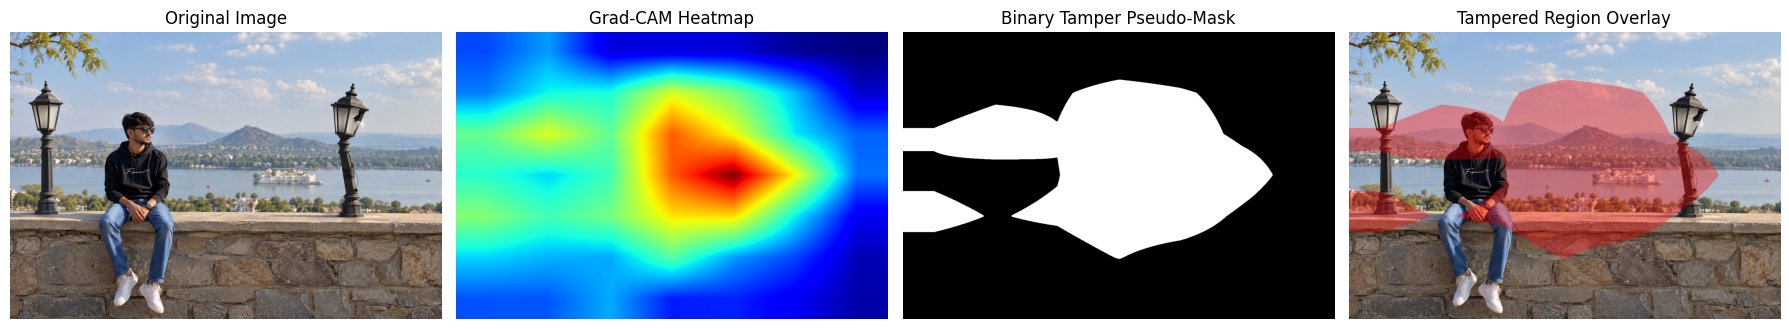


RESULTS SAVED
Pseudo-mask:
/content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (7)_Tamper_PseudoMask.png

Overlay:
/content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (7)_Tamper_Overlay.png

Note: This is a Grad-CAM-derived pseudo-mask,
not a ground-truth pixel-level segmentation mask.


In [ ]:
# ============================================
# CELL 54 — BINARY TAMPER MASK
# ============================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------
# Settings
# --------------------------------------------

MASK_THRESHOLD = 0.45

RESULT_DIR = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(RESULT_DIR, exist_ok=True)

# --------------------------------------------
# Upload image
# --------------------------------------------

from google.colab import files

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image uploaded.")

image_path = list(uploaded.keys())[0]

print("Selected image:", image_path)

# --------------------------------------------
# Load image
# --------------------------------------------

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Image could not be loaded.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

model_img = cv2.resize(
    img_rgb,
    (IMG_SIZE, IMG_SIZE)
).astype(np.float32) / 255.0

input_tensor = np.expand_dims(model_img, axis=0)

# --------------------------------------------
# Prediction
# --------------------------------------------

prediction = final_model.predict(
    input_tensor,
    verbose=0
)[0][0]

result = "TAMPERED" if prediction >= THRESHOLD else "AUTHENTIC"

print("\nPrediction:", result)
print("Tampering Probability:", f"{prediction:.4f}")
print("Classification Threshold:", THRESHOLD)

# --------------------------------------------
# Find MobileNetV2 branch
# --------------------------------------------

mobilenet = None

for layer in final_model.layers:
    if isinstance(layer, tf.keras.Model):
        if "mobilenet" in layer.name.lower():
            mobilenet = layer
            break

if mobilenet is None:
    raise ValueError("MobileNetV2 branch not found.")

# --------------------------------------------
# Find Grad-CAM layer
# --------------------------------------------

target_layer = None

for layer in reversed(mobilenet.layers):
    try:
        if len(layer.output.shape) == 4:
            target_layer = layer
            break
    except:
        pass

if target_layer is None:
    raise ValueError("Suitable Grad-CAM layer not found.")

print("Grad-CAM Layer:", target_layer.name)

# --------------------------------------------
# Grad-CAM
# --------------------------------------------

cam_model = tf.keras.Model(
    inputs=mobilenet.input,
    outputs=[
        target_layer.output,
        mobilenet.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, mobile_features = cam_model(
        input_tensor,
        training=False
    )

    score = tf.reduce_mean(mobile_features)

grads = tape.gradient(
    score,
    conv_outputs
)

if grads is None:
    raise ValueError("Gradients could not be calculated.")

weights = tf.reduce_mean(
    grads,
    axis=(1, 2)
)

cam = tf.reduce_sum(
    conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
    axis=-1
)

cam = tf.maximum(cam, 0)

cam = cam[0].numpy()

if cam.max() > 0:
    cam = cam / cam.max()

# --------------------------------------------
# Resize heatmap
# --------------------------------------------

heatmap = cv2.resize(
    cam,
    (img_rgb.shape[1], img_rgb.shape[0])
)

# --------------------------------------------
# Binary pseudo-mask
# --------------------------------------------

binary_mask = (
    heatmap >= MASK_THRESHOLD
).astype(np.uint8) * 255

# Morphological cleanup
kernel = np.ones((5, 5), np.uint8)

binary_mask = cv2.morphologyEx(
    binary_mask,
    cv2.MORPH_OPEN,
    kernel
)

binary_mask = cv2.morphologyEx(
    binary_mask,
    cv2.MORPH_CLOSE,
    kernel
)

# --------------------------------------------
# Overlay
# --------------------------------------------

overlay = img_rgb.copy()

overlay[binary_mask == 255] = (255, 0, 0)

blended = cv2.addWeighted(
    img_rgb,
    0.65,
    overlay,
    0.35,
    0
)

# --------------------------------------------
# Display
# --------------------------------------------

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Tamper Pseudo-Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(blended)
plt.title("Tampered Region Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# --------------------------------------------
# Save results
# --------------------------------------------

base_name = os.path.splitext(
    os.path.basename(image_path)
)[0]

mask_path = os.path.join(
    RESULT_DIR,
    base_name + "_Tamper_PseudoMask.png"
)

overlay_path = os.path.join(
    RESULT_DIR,
    base_name + "_Tamper_Overlay.png"
)

cv2.imwrite(
    mask_path,
    binary_mask
)

cv2.imwrite(
    overlay_path,
    cv2.cvtColor(blended, cv2.COLOR_RGB2BGR)
)

print("\n============================================")
print("RESULTS SAVED")
print("============================================")
print("Pseudo-mask:")
print(mask_path)
print("\nOverlay:")
print(overlay_path)

print("\nNote: This is a Grad-CAM-derived pseudo-mask,")
print("not a ground-truth pixel-level segmentation mask.")

Total contours detected: 2
Valid tampered regions: 2


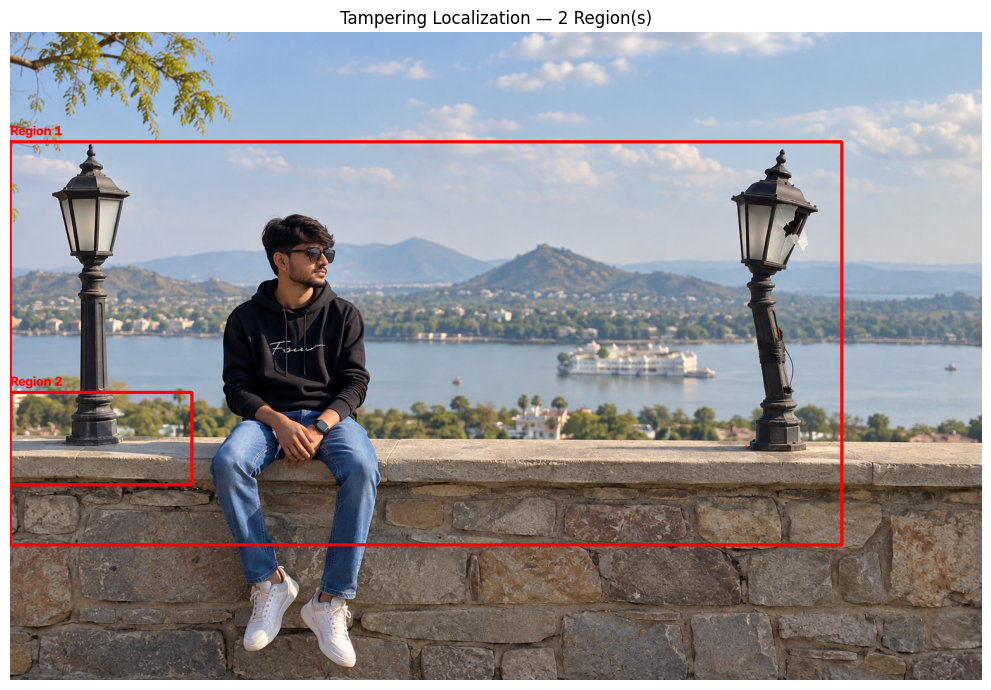


DETECTED TAMPERED REGIONS
Region 1: X=0, Y=173, W=1314, H=637, Area=435895.5
Region 2: X=0, Y=569, W=287, H=146, Area=29880.5

Saved localization image:
/content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (7)_Tamper_Localization_BBox.png
Saved region coordinates:
/content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (7)_Tamper_Regions.csv


In [ ]:
# ============================================
# CELL 55 — CONTOUR + BOUNDING BOX LOCALIZATION
# ============================================

import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------
# Minimum region size
# --------------------------------------------

MIN_AREA = 100

# binary_mask aur img_rgb
# Cell 54 se available hone chahiye

if "binary_mask" not in globals():
    raise ValueError(
        "binary_mask nahi mila. Pehle Cell 54 run karo."
    )

if "img_rgb" not in globals():
    raise ValueError(
        "img_rgb nahi mila. Pehle Cell 54 run karo."
    )

# --------------------------------------------
# Find contours
# --------------------------------------------

contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# --------------------------------------------
# Filter small regions
# --------------------------------------------

valid_contours = []

for contour in contours:

    area = cv2.contourArea(contour)

    if area >= MIN_AREA:
        valid_contours.append(contour)

# Sort largest regions first
valid_contours = sorted(
    valid_contours,
    key=cv2.contourArea,
    reverse=True
)

print("Total contours detected:", len(contours))
print("Valid tampered regions:", len(valid_contours))

# --------------------------------------------
# Draw bounding boxes
# --------------------------------------------

localized_image = img_rgb.copy()

region_info = []

for i, contour in enumerate(valid_contours):

    x, y, w, h = cv2.boundingRect(contour)

    area = cv2.contourArea(contour)

    cv2.rectangle(
        localized_image,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        3
    )

    cv2.putText(
        localized_image,
        f"Region {i+1}",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

    region_info.append({
        "Region": i + 1,
        "X": x,
        "Y": y,
        "Width": w,
        "Height": h,
        "Area": round(area, 2)
    })

# --------------------------------------------
# Display
# --------------------------------------------

plt.figure(figsize=(12, 7))

plt.imshow(localized_image)

plt.title(
    f"Tampering Localization — {len(valid_contours)} Region(s)"
)

plt.axis("off")

plt.tight_layout()

plt.show()

# --------------------------------------------
# Print detected regions
# --------------------------------------------

print("\n============================================")
print("DETECTED TAMPERED REGIONS")
print("============================================")

if len(region_info) == 0:

    print("No sufficiently large suspicious region detected.")

else:

    for region in region_info:
        print(
            f"Region {region['Region']}: "
            f"X={region['X']}, "
            f"Y={region['Y']}, "
            f"W={region['Width']}, "
            f"H={region['Height']}, "
            f"Area={region['Area']}"
        )

# --------------------------------------------
# Save localized image
# --------------------------------------------

base_name = os.path.splitext(
    os.path.basename(image_path)
)[0]

localization_path = os.path.join(
    RESULT_DIR,
    base_name + "_Tamper_Localization_BBox.png"
)

cv2.imwrite(
    localization_path,
    cv2.cvtColor(
        localized_image,
        cv2.COLOR_RGB2BGR
    )
)

print("\nSaved localization image:")
print(localization_path)

# --------------------------------------------
# Save region information
# --------------------------------------------

import pandas as pd

regions_csv = os.path.join(
    RESULT_DIR,
    base_name + "_Tamper_Regions.csv"
)

pd.DataFrame(region_info).to_csv(
    regions_csv,
    index=False
)

print("Saved region coordinates:")
print(regions_csv)

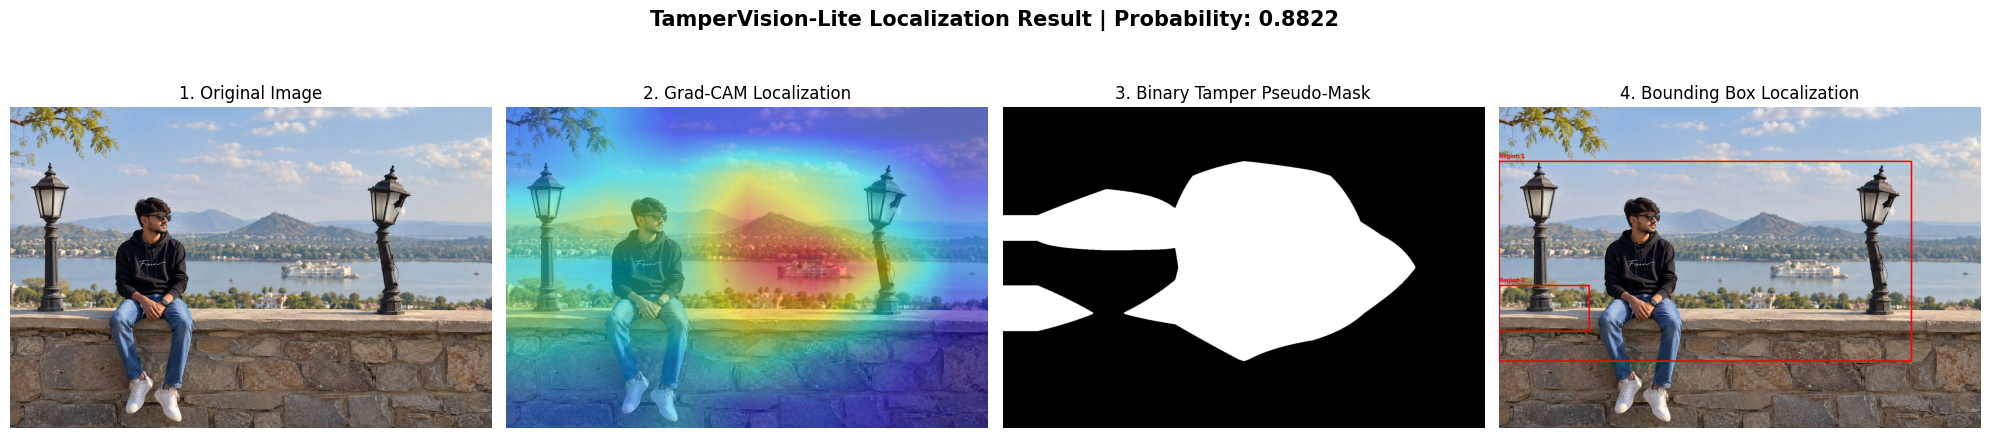

FINAL LOCALIZATION RESULT SAVED
/content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (7)_FINAL_Localization_Result.png


In [ ]:
# ============================================
# CELL 56 — FINAL LOCALIZATION VISUALIZATION
# ============================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------
# Check required variables
# --------------------------------------------

required = [
    "img_rgb",
    "heatmap",
    "binary_mask",
    "localized_image",
    "prediction"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise ValueError(
        "Missing variables: " + str(missing) +
        ". Pehle Cell 54 aur Cell 55 run karo."
    )

# --------------------------------------------
# Create colored heatmap
# --------------------------------------------

heatmap_uint8 = np.uint8(
    heatmap * 255
)

colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

# --------------------------------------------
# Create Grad-CAM overlay
# --------------------------------------------

gradcam_overlay = cv2.addWeighted(
    img_rgb,
    0.55,
    colored_heatmap,
    0.45,
    0
)

# --------------------------------------------
# Final figure
# --------------------------------------------

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# Original
axes[0].imshow(img_rgb)
axes[0].set_title("1. Original Image")
axes[0].axis("off")

# Grad-CAM
axes[1].imshow(gradcam_overlay)
axes[1].set_title("2. Grad-CAM Localization")
axes[1].axis("off")

# Binary mask
axes[2].imshow(
    binary_mask,
    cmap="gray"
)
axes[2].set_title("3. Binary Tamper Pseudo-Mask")
axes[2].axis("off")

# Bounding boxes
axes[3].imshow(localized_image)
axes[3].set_title("4. Bounding Box Localization")
axes[3].axis("off")

fig.suptitle(
    f"TamperVision-Lite Localization Result | "
    f"Probability: {prediction:.4f}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# --------------------------------------------
# Save final visualization
# --------------------------------------------

base_name = os.path.splitext(
    os.path.basename(image_path)
)[0]

final_path = os.path.join(
    RESULT_DIR,
    base_name + "_FINAL_Localization_Result.png"
)

plt.savefig(
    final_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("============================================")
print("FINAL LOCALIZATION RESULT SAVED")
print("============================================")
print(final_path)

Saving ChatGPT Image Sep 20, 2026, 12_22_10 PM.png to ChatGPT Image Sep 20, 2026, 12_22_10 PM (8).png
        TAMPERVISION-LITE RESULT
Prediction : TAMPERED
Probability: 88.22%
Threshold  : 0.50


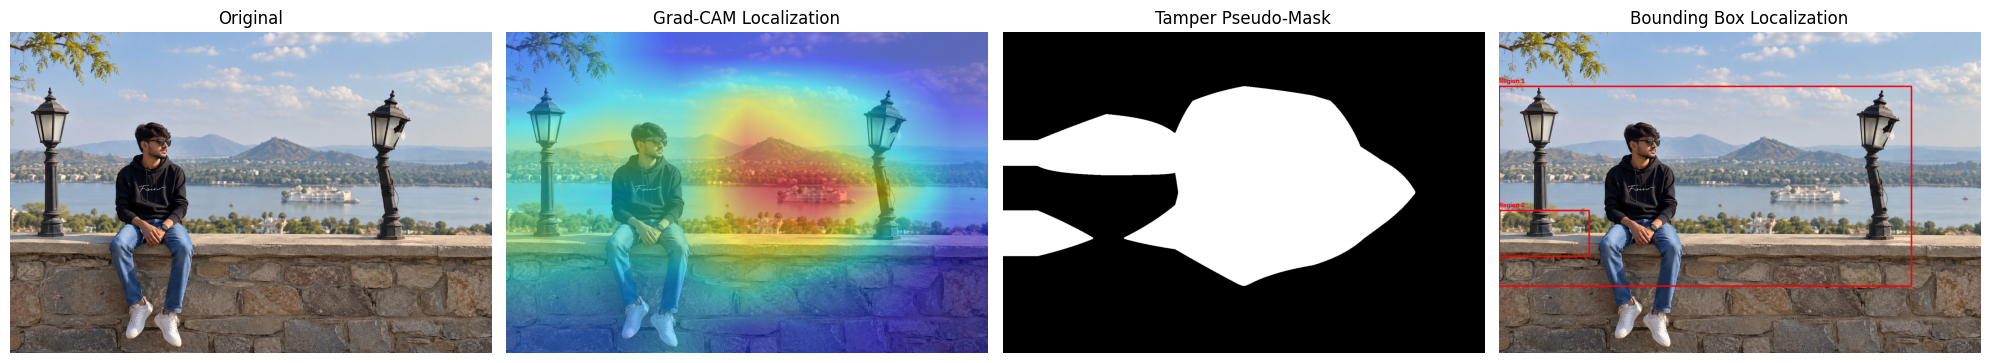


Detected suspicious regions: 2
Pseudo-mask saved: /content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (8)_PseudoMask.png
Localization saved: /content/drive/MyDrive/TamperVision_Results/ChatGPT Image Sep 20, 2026, 12_22_10 PM (8)_Localization.png

NOTE:
Localization is Grad-CAM based.
Mask is a pseudo-mask, not ground-truth segmentation.


In [ ]:
# ============================================
# CELL 57 — FINAL ALL-IN-ONE DEMO
# ============================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

RESULT_DIR = "/content/drive/MyDrive/TamperVision_Results"
os.makedirs(RESULT_DIR, exist_ok=True)

THRESHOLD = 0.50
MASK_THRESHOLD = 0.45
MIN_AREA = 100

# ---------- Upload ----------
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

image_path = list(uploaded.keys())[0]

# ---------- Load ----------
img = cv2.imread(image_path)

if img is None:
    raise ValueError("Invalid image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

model_img = cv2.resize(
    img_rgb,
    (IMG_SIZE, IMG_SIZE)
).astype(np.float32) / 255.0

x = np.expand_dims(model_img, axis=0)

# ---------- Prediction ----------
prob = float(final_model.predict(x, verbose=0)[0][0])

prediction = (
    "TAMPERED"
    if prob >= THRESHOLD
    else "AUTHENTIC"
)

print("==========================================")
print("        TAMPERVISION-LITE RESULT")
print("==========================================")
print("Prediction :", prediction)
print("Probability:", f"{prob*100:.2f}%")
print("Threshold  :", f"{THRESHOLD:.2f}")

# ---------- MobileNet branch ----------
mobilenet = None

for layer in final_model.layers:
    if isinstance(layer, tf.keras.Model):
        if "mobilenet" in layer.name.lower():
            mobilenet = layer
            break

if mobilenet is None:
    raise ValueError("MobileNetV2 branch not found.")

# ---------- Grad-CAM layer ----------
target_layer = None

for layer in reversed(mobilenet.layers):
    try:
        if len(layer.output.shape) == 4:
            target_layer = layer
            break
    except:
        pass

if target_layer is None:
    raise ValueError("Grad-CAM layer not found.")

cam_model = tf.keras.Model(
    mobilenet.input,
    [target_layer.output, mobilenet.output]
)

# ---------- Grad-CAM ----------
with tf.GradientTape() as tape:

    conv_outputs, features = cam_model(
        x,
        training=False
    )

    score = tf.reduce_mean(features)

grads = tape.gradient(
    score,
    conv_outputs
)

if grads is None:
    raise ValueError("Gradients unavailable.")

weights = tf.reduce_mean(
    grads,
    axis=(1, 2)
)

cam = tf.reduce_sum(
    conv_outputs *
    weights[:, None, None, :],
    axis=-1
)

cam = tf.maximum(cam, 0)[0].numpy()

if cam.max() > 0:
    cam /= cam.max()

heatmap = cv2.resize(
    cam,
    (img_rgb.shape[1], img_rgb.shape[0])
)

# ---------- Binary pseudo-mask ----------
mask = (
    heatmap >= MASK_THRESHOLD
).astype(np.uint8) * 255

kernel = np.ones((5, 5), np.uint8)

mask = cv2.morphologyEx(
    mask,
    cv2.MORPH_OPEN,
    kernel
)

mask = cv2.morphologyEx(
    mask,
    cv2.MORPH_CLOSE,
    kernel
)

# ---------- Bounding boxes ----------
contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

localized = img_rgb.copy()

regions = 0

for contour in sorted(
    contours,
    key=cv2.contourArea,
    reverse=True
):

    area = cv2.contourArea(contour)

    if area < MIN_AREA:
        continue

    x1, y1, w, h = cv2.boundingRect(contour)

    regions += 1

    cv2.rectangle(
        localized,
        (x1, y1),
        (x1+w, y1+h),
        (255, 0, 0),
        3
    )

    cv2.putText(
        localized,
        f"Region {regions}",
        (x1, max(y1-10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

# ---------- Heatmap ----------
heatmap_color = cv2.applyColorMap(
    np.uint8(heatmap * 255),
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

gradcam_overlay = cv2.addWeighted(
    img_rgb,
    0.55,
    heatmap_color,
    0.45,
    0
)

# ---------- Display ----------
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gradcam_overlay)
plt.title("Grad-CAM Localization")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(mask, cmap="gray")
plt.title("Tamper Pseudo-Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(localized)
plt.title("Bounding Box Localization")
plt.axis("off")

plt.tight_layout()
plt.show()

# ---------- Save ----------
base = os.path.splitext(
    os.path.basename(image_path)
)[0]

mask_path = os.path.join(
    RESULT_DIR,
    base + "_PseudoMask.png"
)

localization_path = os.path.join(
    RESULT_DIR,
    base + "_Localization.png"
)

cv2.imwrite(
    mask_path,
    mask
)

cv2.imwrite(
    localization_path,
    cv2.cvtColor(
        localized,
        cv2.COLOR_RGB2BGR
    )
)

print("\nDetected suspicious regions:", regions)
print("Pseudo-mask saved:", mask_path)
print("Localization saved:", localization_path)

print("\nNOTE:")
print("Localization is Grad-CAM based.")
print("Mask is a pseudo-mask, not ground-truth segmentation.")

In [ ]:
# ============================================
# CELL 58 — FINAL PROJECT SUMMARY
# ============================================

print("""
====================================================
              TAMPERVISION-LITE
              FINAL MODEL
====================================================

Architecture:
SRM + MobileNetV2 Feature Fusion

Fine-Tuning:
Last 30 MobileNetV2 layers

Input:
224 x 224 x 3

----------------------------------------------------
FINAL TEST RESULTS
----------------------------------------------------

Accuracy          : 80.89%
Precision         : 57.32%
Tampered Recall   : 45.48%
F1-Score          : 50.72%
ROC-AUC           : 79.14%
PR-AUC            : 52.21%

----------------------------------------------------
LOCALIZATION
----------------------------------------------------

Grad-CAM          : YES
Pseudo-Mask       : YES
Contour Detection : YES
Bounding Boxes    : YES

Pixel-level Ground-Truth
Segmentation      : NO

----------------------------------------------------
MODEL FILE
----------------------------------------------------

/content/drive/MyDrive/
TamperVision_SRM_MobileNet_FineTuned_best.keras

====================================================
STATUS: CORE PROJECT COMPLETE
====================================================
""")


              TAMPERVISION-LITE
              FINAL MODEL

Architecture:
SRM + MobileNetV2 Feature Fusion

Fine-Tuning:
Last 30 MobileNetV2 layers

Input:
224 x 224 x 3

----------------------------------------------------
FINAL TEST RESULTS
----------------------------------------------------

Accuracy          : 80.89%
Precision         : 57.32%
Tampered Recall   : 45.48%
F1-Score          : 50.72%
ROC-AUC           : 79.14%
PR-AUC            : 52.21%

----------------------------------------------------
LOCALIZATION
----------------------------------------------------

Grad-CAM          : YES
Pseudo-Mask       : YES
Contour Detection : YES
Bounding Boxes    : YES

Pixel-level Ground-Truth
Segmentation      : NO

----------------------------------------------------
MODEL FILE
----------------------------------------------------

/content/drive/MyDrive/
TamperVision_SRM_MobileNet_FineTuned_best.keras

STATUS: CORE PROJECT COMPLETE



In [ ]:
# ============================================
# CELL 59 — SAVE FINAL METADATA
# ============================================

import pickle
import os

metadata = {
    "project": "TamperVision-Lite",
    "architecture": "SRM + MobileNetV2 Fusion",
    "fine_tuning": "Last 30 MobileNetV2 layers",
    "input_size": "224x224x3",

    "accuracy": 80.89,
    "precision": 57.32,
    "tampered_recall": 45.48,
    "f1_score": 50.72,
    "roc_auc": 79.14,
    "pr_auc": 52.21,

    "threshold": 0.50,

    "localization": "Grad-CAM",
    "pseudo_mask": True,
    "bounding_box": True,
    "pixel_level_segmentation": False,

    "model_path":
        "/content/drive/MyDrive/"
        "TamperVision_SRM_MobileNet_FineTuned_best.keras"
}

pkl_path = (
    "/content/drive/MyDrive/"
    "TamperVision_Results/"
    "TamperVision_Final_Metadata.pkl"
)

with open(pkl_path, "wb") as f:
    pickle.dump(metadata, f)

print("Final metadata saved:")
print(pkl_path)

Final metadata saved:
/content/drive/MyDrive/TamperVision_Results/TamperVision_Final_Metadata.pkl
